# UNIVERSIDAD INDUSTRIAL DE SANTANDER (UIS)
## FACULTAD DE CIENCIAS — ESCUELA DE MATEMÁTICAS
### ESTADÍSTICA II — TAREA 2: MODELOS DE REGRESIÓN EN LENGUAJE PYTHON

* **Profesor:** Andrés Ríos-Gutiérrez
* **Integrantes del Grupo:**
  * **Juan Jaimes**
  * **Marco Galvis**
  * **Maria Sarabia**
  * **Juan Prada**
* **Enlace al Repositorio en GitHub:** [https://github.com/juanes2809/Tarea-2-Estadistica-II](https://github.com/juanes2809/Tarea-2-Estadistica-II)
* **Enlace Directo al Cuaderno Jupyter:** [https://github.com/juanes2809/Tarea-2-Estadistica-II/blob/main/Tarea_2_Estadistica_II.ipynb](https://github.com/juanes2809/Tarea-2-Estadistica-II/blob/main/Tarea_2_Estadistica_II.ipynb)

---

## 1. Introducción y Contexto de la Base de Datos (`SB11_20231.TXT`)

### 1.1 Origen de los Datos y Diseño Poblacional
El presente informe-cuaderno desarrolla paso a paso el análisis estadístico y computacional de la **Tarea 2 de Estadística II**, integrando en un solo documento el código en lenguaje Python, sus resultados, las gráficas generadas en tiempo de ejecución y la interpretación estadística y contextual **línea a línea**.

Se analiza la base de datos oficial `SB11_20231.TXT` suministrada por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)** dentro de la serie *Saber al Detalle*. Este archivo contiene los microdatos censales del **Examen de Estado de la Educación Media Saber 11° correspondiente al primer semestre de 2023 (segunda cohorte 2023-1, Calendario B)**. A diferencia del Calendario A (aplicado en el segundo semestre mayoritariamente en colegios oficiales), la cohorte `2023-1` evalúa principalmente a colegios privados (`NO OFICIAL`) y bilingües de Calendario B concentrados en departamentos como Valle del Cauca ($49.5\%$), Bogotá D.C. ($22.5\%$), Antioquia ($5.0\%$), Atlántico ($4.7\%$), Cauca ($4.6\%$), Cundinamarca ($3.9\%$) y **Santander ($168$ estudiantes)**.

### 1.2 Variables de Estudio
* **Variable Respuesta ($Y$): `ESTU_INSE_INDIVIDUAL`** (*Índice de Nivel Socioeconómico Individual*). Es una medida continua (escala $0$ a $100$) estimada por el ICFES mediante Teoría de Respuesta al Ítem (TRI) a partir del cuestionario sociodemográfico de inscripción (nivel educativo y ocupación de los padres, estrato de la vivienda, acceso a internet, computador, automóvil y libros en el hogar). El ICFES lo clasifica en cuatro niveles: **NSE 1** ($\le 40.99$), **NSE 2** ($41.00$–$51.20$), **NSE 3** ($51.21$–$62.89$) y **NSE 4** ($\ge 62.90$).
* **Variables Explicativas Candidatas ($X_1, \dots, X_5$):** Puntajes obtenidos por el estudiante en cada una de las cinco pruebas cognitivas del examen (escala discreta de $0$ a $100$ puntos):
  1. `PUNT_LECTURA_CRITICA`: Comprensión lectora literal, inferencial y crítica.
  2. `PUNT_MATEMATICAS`: Razonamiento cuantitativo, formulación y resolución de problemas.
  3. `PUNT_C_NATURALES`: Competencias en física, química, biología y ciencia, tecnología y sociedad.
  4. `PUNT_SOCIALES_CIUDADANAS`: Pensamiento social, multiperspectivismo y pensamiento sistémico.
  5. `PUNT_INGLES`: Competencia comunicativa en lengua inglesa alineada con el Marco Común Europeo (A-, A1, A2, B1 y B+).

---

### 1.3 Carga de la Base de Datos e Interpretación Línea a Línea
En Google Colaboratory, la guía indica cargar el archivo con las siguientes líneas:
```python
from google.colab import files # Importa el módulo de carga de archivos locales a la máquina virtual de Colab
uploaded = files.upload()      # Abre el botón interactivo para subir 'SB11_20231.TXT' como diccionario de bytes
import pandas as pd            # Importa pandas para manejo de estructuras tabulares (DataFrames)
import io                      # Importa io para transformar bytes en memoria en un flujo de lectura
datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']),
                          delimiter='¬') # Lee el archivo separando las columnas por el carácter '¬'
```
A continuación ejecutamos la carga de `SB11_20231.TXT` de forma compatible tanto con ejecución local/GitHub como con Google Colab:

In [1]:
# Importación de librerías para análisis estadístico, econométrico y redes neuronales
import io
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Configuración visual de los gráficos del cuaderno
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Lectura de la base de datos SB11_20231.TXT usando el delimitador '¬'
if os.path.exists('SB11_20231.TXT'):
    datos_icfes = pd.read_csv('SB11_20231.TXT', delimiter='¬', engine='python')
else:
    from google.colab import files
    uploaded = files.upload()
    datos_icfes = pd.read_csv(io.BytesIO(uploaded['SB11_20231.TXT']), delimiter='¬', engine='python')

print(f"Total de registros cargados en datos_icfes: {datos_icfes.shape[0]:,} filas x {datos_icfes.shape[1]} columnas")
datos_icfes[['ESTU_CONSECUTIVO', 'COLE_NATURALEZA', 'ESTU_DEPTO_RESIDE',
             'PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES',
             'PUNT_SOCIALES_CIUDADANAS', 'PUNT_INGLES', 'ESTU_INSE_INDIVIDUAL']].head()

Total de registros cargados en datos_icfes: 12,704 filas x 83 columnas


,ESTU_CONSECUTIVO,COLE_NATURALEZA,ESTU_DEPTO_RESIDE,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,ESTU_INSE_INDIVIDUAL
0,SB11202310019049,NO OFICIAL,CUNDINAMARCA,100,83,77,77,87.0,67.532814
1,SB11202310017318,NO OFICIAL,VALLE,67,58,68,68,NaN,47.223972
2,SB11202310030916,NO OFICIAL,VALLE,37,42,35,35,NaN,67.695519
3,SB11202310074169,NO OFICIAL,VALLE,45,41,41,27,58.0,41.863163
4,SB11202310044933,NO OFICIAL,VALLE,53,55,41,56,69.0,51.223795


---
## 2. Eliminación de Valores Faltantes en el Análisis Estadístico (`icfes_sin_nan`)

### Explicación Línea a Línea del Código de Filtrado
El algoritmo suministrado en la guía construye el subconjunto sin datos faltantes `icfes_sin_nan` mediante indexación booleana compuesta:
* `datos_icfes['VARIABLE'].isna()`: Verifica registro por registro si el valor es nulo (`NaN`), retornando `True` cuando el dato falta y `False` cuando está presente.
* `~` (operador de negación lógica bit a bit en `pandas`): Invierte el valor de verdad de la serie booleana, de modo que `~datos_icfes['VARIABLE'].isna()` toma el valor `True` únicamente para los estudiantes que **sí tienen dato válido** en esa columna.
* `&` (operador de intersección lógica vectorial): Exige que se cumplan **simultáneamente** las seis condiciones de validez (que no falte la variable respuesta `ESTU_INSE_INDIVIDUAL` ni ninguna de las cinco pruebas académicas).

In [2]:
# Definición de la variable respuesta y las 5 variables explicativas
var_respuesta = 'ESTU_INSE_INDIVIDUAL'
vars_explicativas = [
    'PUNT_LECTURA_CRITICA',
    'PUNT_MATEMATICAS',
    'PUNT_C_NATURALES',
    'PUNT_SOCIALES_CIUDADANAS',
    'PUNT_INGLES'
]
todas_vars = [var_respuesta] + vars_explicativas

# Diagnóstico de valores faltantes (NaN) por columna antes de limpiar
conteo_nan = pd.DataFrame({
    'Datos_Faltantes (NaN)': datos_icfes[todas_vars].isna().sum(),
    'Porcentaje_NaN (%)': (datos_icfes[todas_vars].isna().mean() * 100).round(2),
    'Datos_Validos': datos_icfes[todas_vars].notna().sum()
})
print("=== CONTEO DE VALORES FALTANTES EN datos_icfes (N = 12,704) ===")
display(conteo_nan)

# Código exacto de la guía para generar el elemento icfes_sin_nan
icfes_sin_nan = datos_icfes[(~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
                            (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
                            (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
                            (~datos_icfes['PUNT_C_NATURALES'].isna()) &
                            (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
                            (~datos_icfes['PUNT_INGLES'].isna())].copy()

print(f"Registros totales en datos_icfes      : {len(datos_icfes):,}")
print(f"Registros limpios en icfes_sin_nan    : {len(icfes_sin_nan):,} ({len(icfes_sin_nan)/len(datos_icfes)*100:.2f}%)")
print(f"Registros excluidos por valores NaN   : {len(datos_icfes) - len(icfes_sin_nan):,} ({(1 - len(icfes_sin_nan)/len(datos_icfes))*100:.2f}%)")

# Resumen descriptivo del conjunto depurado icfes_sin_nan
desc_sin_nan = icfes_sin_nan[todas_vars].describe().T
desc_sin_nan['Asimetría'] = icfes_sin_nan[todas_vars].skew()
print("\n=== ESTADÍSTICAS DESCRIPTIVAS DE icfes_sin_nan (n = 11,853) ===")
display(desc_sin_nan[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'Asimetría']].round(2))

=== CONTEO DE VALORES FALTANTES EN datos_icfes (N = 12,704) ===


,Datos_Faltantes (NaN),Porcentaje_NaN (%),Datos_Validos
ESTU_INSE_INDIVIDUAL,849,6.68,11855
PUNT_LECTURA_CRITICA,0,0.00,12704
PUNT_MATEMATICAS,0,0.00,12704
PUNT_C_NATURALES,0,0.00,12704
PUNT_SOCIALES_CIUDADANAS,0,0.00,12704
PUNT_INGLES,2,0.02,12702


Registros totales en datos_icfes      : 12,704
Registros limpios en icfes_sin_nan    : 11,853 (93.30%)
Registros excluidos por valores NaN   : 851 (6.70%)

=== ESTADÍSTICAS DESCRIPTIVAS DE icfes_sin_nan (n = 11,853) ===


,count,mean,std,min,25%,50%,75%,max,Asimetría
ESTU_INSE_INDIVIDUAL,11853.0,63.01,7.43,23.42,58.19,63.99,68.54,83.01,-0.64
PUNT_LECTURA_CRITICA,11853.0,64.62,9.23,25.00,59.00,66.00,71.00,100.00,-0.39
PUNT_MATEMATICAS,11853.0,64.23,11.84,16.00,57.00,65.00,72.00,100.00,-0.17
PUNT_C_NATURALES,11853.0,61.20,10.22,27.00,55.00,62.00,69.00,100.00,-0.40
PUNT_SOCIALES_CIUDADANAS,11853.0,61.02,11.06,24.00,54.00,62.00,69.00,100.00,-0.49
PUNT_INGLES,11853.0,73.11,13.93,26.00,64.00,77.00,82.00,100.00,-0.48


### Justificación Estadística y Contextual de la Limpieza de Datos
1. **Origen de los $849$ valores faltantes en `ESTU_INSE_INDIVIDUAL` ($6.68\%$):** De acuerdo con la documentación técnica del ICFES y la literatura de datos faltantes (Little & Rubin, 2019), el índice socioeconómico se estima a partir del cuestionario sociodemográfico que el estudiante diligencia al inscribirse. Cuando el evaluado omite dicho cuestionario, el sistema asigna `NaN`. Al observar que los $849$ estudiantes sin INSE sí presentaron las cinco pruebas cognitivas pero tienen promedios académicos ligeramente menores ($69.69$ en Inglés frente a $73.11$ en los datos completos), se concluye que el mecanismo de pérdida es **MAR (*Missing At Random*)**, pues depende de covariables observadas (los puntajes académicos). Esto justifica entrenar los modelos sobre `icfes_sin_nan` ($n = 11,853$) y posteriormente **imputar** estos $849$ registros (`icfes_connan`).
2. **Origen de los $2$ valores faltantes en `PUNT_INGLES` ($0.02\%$):** Corresponden a dos estudiantes que asistieron a la primera sesión del examen pero no completaron el módulo de Inglés en la segunda sesión. Su eliminación es indispensable dado que los algoritmos de regresión lineal y redes neuronales requieren matrices de diseño $\mathbf{X}$ sin entradas vacías.
3. **Datos atípicos y contexto de Calendario B:** Se observan algunos puntajes mínimos de $0.00$ (evaluados que dejaron en blanco un área específica) y distribuciones con asimetría negativa ($-0.64$ en el INSE). El promedio de `ESTU_INSE_INDIVIDUAL` ($63.01$) y de `PUNT_INGLES` ($73.11$) es alto porque más del $95\%$ de los estudiantes de Calendario B provienen de colegios privados.

---
## 3. Selección de Variables Explicativas a partir de los Diagramas de Dispersión

Construimos los diagramas de dispersión entre la variable respuesta `ESTU_INSE_INDIVIDUAL` (eje $Y$) y cada una de las cinco variables explicativas (eje $X$), superponiendo la recta de regresión lineal simple ajustada por mínimos cuadrados ordinarios ($\hat{Y} = \hat{\beta}_0 + \hat{\beta}_1 X$) para inspeccionar visualmente qué variables presentan una relación funcional más estrecha.

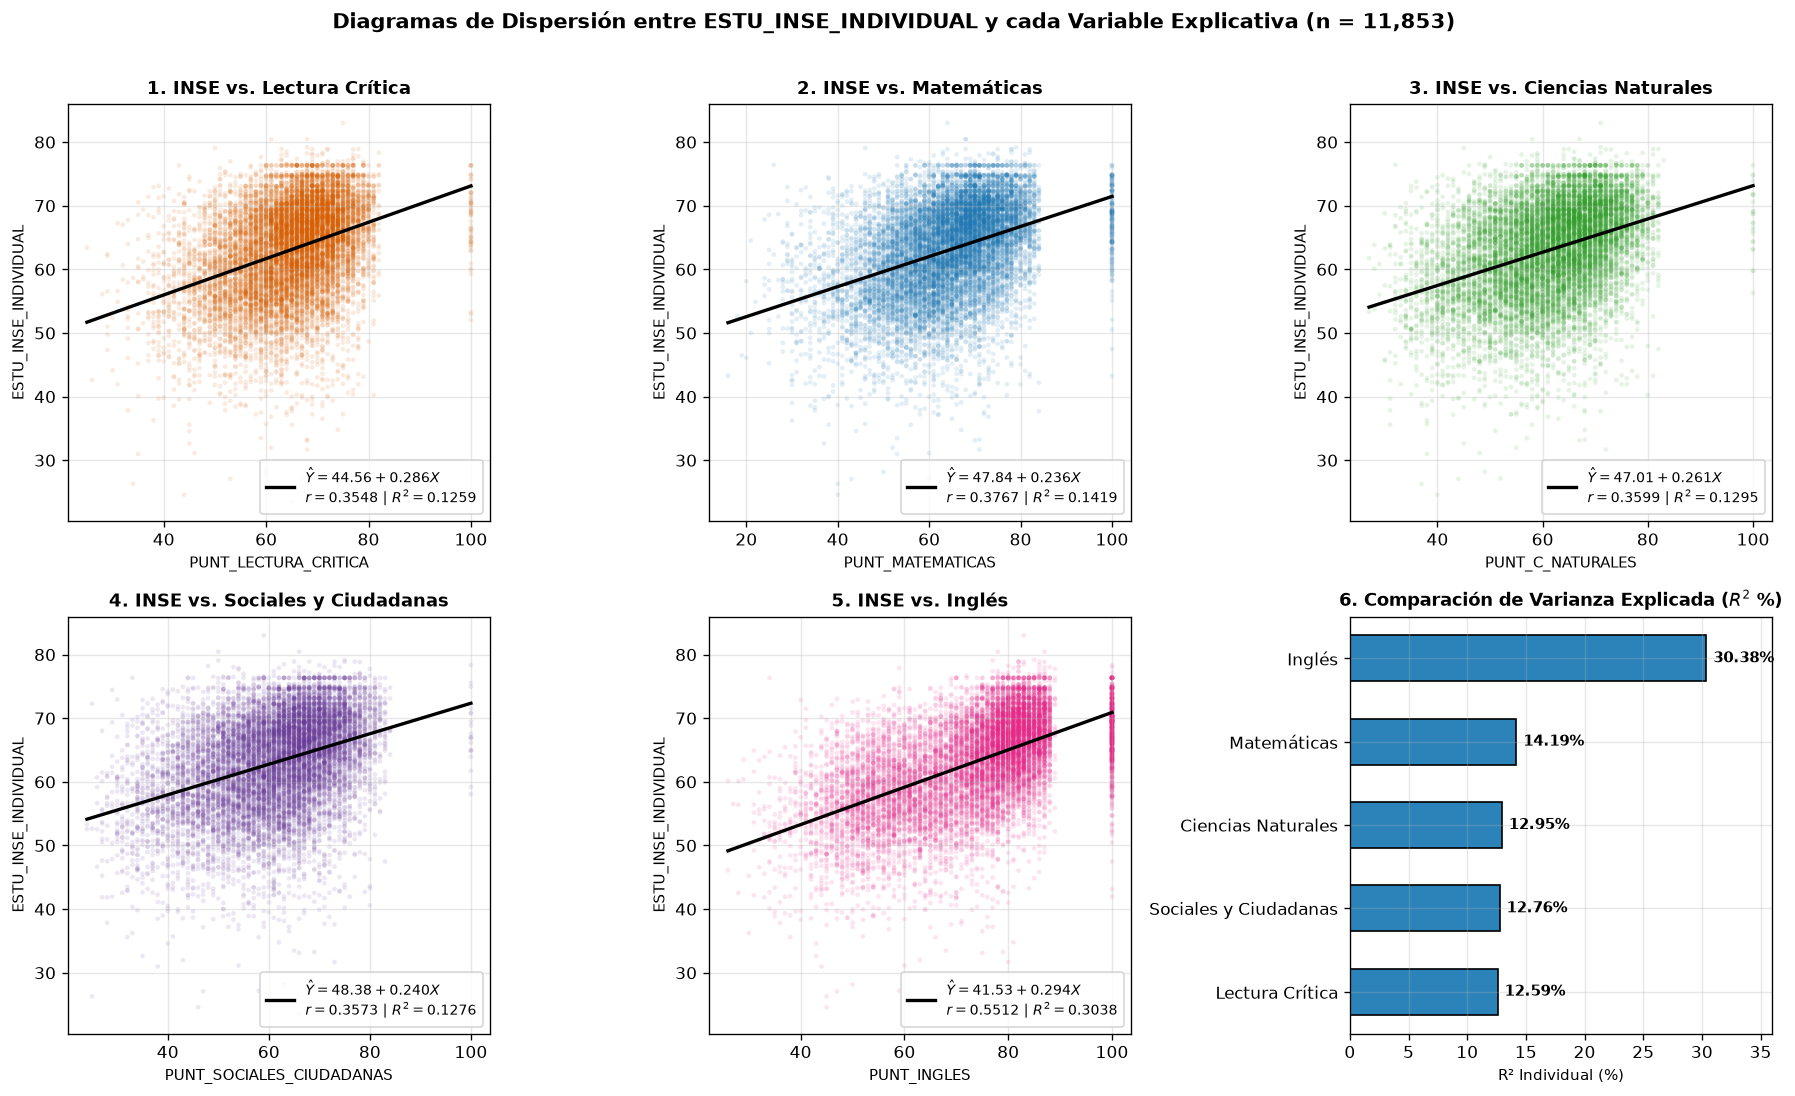

,Variable Explicativa (X),Intercepto (β0),Pendiente (β1),Correlación (r),R² Individual,Varianza Explicada (%)
4,PUNT_INGLES,41.5335,0.2937,0.5512,0.3038,30.3772
1,PUNT_MATEMATICAS,47.8383,0.2362,0.3767,0.1419,14.1877
2,PUNT_C_NATURALES,47.0070,0.2615,0.3599,0.1295,12.9496
3,PUNT_SOCIALES_CIUDADANAS,48.3768,0.2398,0.3573,0.1276,12.7639
0,PUNT_LECTURA_CRITICA,44.5603,0.2855,0.3548,0.1259,12.5868


In [3]:
# Generación de los 5 diagramas de dispersión entre ESTU_INSE_INDIVIDUAL y cada variable explicativa
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
colores = ['#d95f02', '#1f78b4', '#33a02c', '#6a3d9a', '#e7298a']
nombres_cortos = {
    'PUNT_LECTURA_CRITICA': 'Lectura Crítica',
    'PUNT_MATEMATICAS': 'Matemáticas',
    'PUNT_C_NATURALES': 'Ciencias Naturales',
    'PUNT_SOCIALES_CIUDADANAS': 'Sociales y Ciudadanas',
    'PUNT_INGLES': 'Inglés'
}

tabla_rectas = []
for i, (col, color) in enumerate(zip(vars_explicativas, colores)):
    ax = axes[i]
    x = icfes_sin_nan[col]
    y = icfes_sin_nan[var_respuesta]
    
    # Ajuste lineal simple Y = β0 + β1*X
    pendiente, intercepto, r_val, p_val, err_std = stats.linregress(x, y)
    r2_simple = r_val ** 2
    tabla_rectas.append({
        'Variable Explicativa (X)': col,
        'Intercepto (β0)': intercepto,
        'Pendiente (β1)': pendiente,
        'Correlación (r)': r_val,
        'R² Individual': r2_simple,
        'Varianza Explicada (%)': r2_simple * 100
    })
    
    # Nube de puntos y recta de tendencia
    ax.scatter(x, y, alpha=0.12, s=8, color=color, edgecolors='none', rasterized=True)
    x_linea = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_linea, intercepto + pendiente * x_linea, color='black', linewidth=2,
            label=f'$\hat{{Y}} = {intercepto:.2f} + {pendiente:.3f}X$\n$r = {r_val:.4f}$ | $R^2 = {r2_simple:.4f}$')
    ax.set_title(f'{i+1}. INSE vs. {nombres_cortos[col]}', fontsize=10.5, fontweight='bold')
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel('ESTU_INSE_INDIVIDUAL', fontsize=9)
    ax.legend(loc='lower right', fontsize=8.5, frameon=True, facecolor='white')

# Sexto panel: Comparación del R² individual de cada diagrama de dispersión
ax6 = axes[5]
df_rectas = pd.DataFrame(tabla_rectas).sort_values(by='R² Individual', ascending=True)
bars = ax6.barh([nombres_cortos[v] for v in df_rectas['Variable Explicativa (X)']],
                df_rectas['Varianza Explicada (%)'], color='#2b83ba', edgecolor='black', height=0.55)
ax6.set_title('6. Comparación de Varianza Explicada ($R^2$ %)', fontsize=10.5, fontweight='bold')
ax6.set_xlabel('R² Individual (%)', fontsize=9)
ax6.set_xlim(0, 36)
for b in bars:
    ax6.text(b.get_width() + 0.6, b.get_y() + b.get_height()/2, f'{b.get_width():.2f}%', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Diagramas de Dispersión entre ESTU_INSE_INDIVIDUAL y cada Variable Explicativa (n = 11,853)', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figuras/fig2_diagramas_dispersion_2d.png', bbox_inches='tight', dpi=300)
plt.show()

display(df_rectas.sort_values(by='R² Individual', ascending=False).round(4))

### Interpretación de los Diagramas de Dispersión
1. **`PUNT_INGLES` es la variable con relación lineal más fuerte:** En el Panel 5 se observa la nube de puntos más definida y con mayor pendiente ($\hat{\beta}_1 = 0.2937$), explicando por sí sola el **$30.38\%$ de la variabilidad del INSE** ($R^2 = 0.3038$). Además, muestra que puntajes de inglés superiores a $80$ (bilingüismo B1/B+) pertenecen casi exclusivamente a estudiantes con $\text{INSE} > 60$ (Nivel NSE 4).
2. **`PUNT_MATEMATICAS` ocupa el segundo lugar:** Presenta una tendencia positiva clara ($\hat{\beta}_1 = 0.2362$, $R^2 = 0.1419$, explicando el **$14.19\%$** de la varianza).
3. **Las otras tres pruebas (`PUNT_C_NATURALES`, `PUNT_SOCIALES_CIUDADANAS` y `PUNT_LECTURA_CRITICA`):** Presentan mayor dispersión vertical (mayor varianza residual para cada puntaje $X$) y explican porcentajes menores y muy similares entre sí ($12.95\%$, $12.76\%$ y $12.59\%$). Por tanto, visualmente se preseleccionan **`PUNT_INGLES`** y **`PUNT_MATEMATICAS`** como las variables más explicativas.

---
## 4. Selección de Variables Explicativas a partir de los Coeficientes de Correlación de Pearson, de Kendall y de Spearman

Calculamos los tres coeficientes de correlación para cuantificar la fuerza de asociación tanto lineal (paramétrica) como monótona por rangos (no paramétrica):
* **Pearson ($r$):** Mide asociación estrictamente lineal entre variables cuantitativas.
* **Kendall ($\tau$):** Mide asociación monótona basada en pares concordantes y discordantes; es robusta frente a datos atípicos.
* **Spearman ($\rho$):** Correlación de Pearson aplicada a los rangos de los datos; detecta relaciones monótonas crecientes aunque presenten curvatura.

In [4]:
# Cálculo de las matrices de correlación de Pearson, Kendall y Spearman
matriz_pearson  = icfes_sin_nan[todas_vars].corr(method='pearson')
matriz_kendall  = icfes_sin_nan[todas_vars].corr(method='kendall')
matriz_spearman = icfes_sin_nan[todas_vars].corr(method='spearman')

# Tabla resumen de correlaciones y p-valores frente a la variable respuesta ESTU_INSE_INDIVIDUAL
filas_corr = []
for col in vars_explicativas:
    r_p, p_p = stats.pearsonr(icfes_sin_nan[col], icfes_sin_nan[var_respuesta])
    r_k, p_k = stats.kendalltau(icfes_sin_nan[col], icfes_sin_nan[var_respuesta])
    r_s, p_s = stats.spearmanr(icfes_sin_nan[col], icfes_sin_nan[var_respuesta])
    filas_corr.append({
        'Variable Explicativa': col,
        'Pearson (r)': r_p,
        'Kendall (τ)': r_k,
        'Spearman (ρ)': r_s,
        'Valor-p (Significancia)': p_p
    })

df_correlaciones = pd.DataFrame(filas_corr).sort_values(by='Pearson (r)', ascending=False)
df_correlaciones['Orden'] = ['1°', '2°', '3°', '4°', '5°']
print("=== COEFICIENTES DE CORRELACIÓN CON ESTU_INSE_INDIVIDUAL ===")
display(df_correlaciones[['Orden', 'Variable Explicativa', 'Pearson (r)', 'Kendall (τ)', 'Spearman (ρ)', 'Valor-p (Significancia)']].round(4))

print("\n=== MATRIZ DE CORRELACIÓN DE PEARSON COMPLETA (ANÁLISIS DE COLINEALIDAD) ===")
display(matriz_pearson.round(4))

=== COEFICIENTES DE CORRELACIÓN CON ESTU_INSE_INDIVIDUAL ===


,Orden,Variable Explicativa,Pearson (r),Kendall (τ),Spearman (ρ),Valor-p (Significancia)
4,1°,PUNT_INGLES,0.5512,0.3958,0.5657,0.0
1,2°,PUNT_MATEMATICAS,0.3767,0.2711,0.3939,0.0
2,3°,PUNT_C_NATURALES,0.3599,0.2505,0.3647,0.0
3,4°,PUNT_SOCIALES_CIUDADANAS,0.3573,0.2488,0.3624,0.0
0,5°,PUNT_LECTURA_CRITICA,0.3548,0.2464,0.3576,0.0



=== MATRIZ DE CORRELACIÓN DE PEARSON COMPLETA (ANÁLISIS DE COLINEALIDAD) ===


,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
ESTU_INSE_INDIVIDUAL,1.0000,0.3548,0.3767,0.3599,0.3573,0.5512
PUNT_LECTURA_CRITICA,0.3548,1.0000,0.6924,0.7370,0.7724,0.6451
PUNT_MATEMATICAS,0.3767,0.6924,1.0000,0.7945,0.7109,0.6263
PUNT_C_NATURALES,0.3599,0.7370,0.7945,1.0000,0.7877,0.6294
PUNT_SOCIALES_CIUDADANAS,0.3573,0.7724,0.7109,0.7877,1.0000,0.6292
PUNT_INGLES,0.5512,0.6451,0.6263,0.6294,0.6292,1.0000


### Interpretación de los Coeficientes de Correlación
1. **Jerarquía idéntica en los tres métodos:** Tanto Pearson ($r$), como Kendall ($\tau$) y Spearman ($\rho$) ordenan las variables exactamente igual (todas con $p < 0.0001$):
   $$\text{PUNT\_INGLES} > \text{PUNT\_MATEMATICAS} > \text{PUNT\_C\_NATURALES} > \text{PUNT\_SOCIALES\_CIUDADANAS} > \text{PUNT\_LECTURA\_CRITICA}$$
2. **¿Por qué Spearman ($\rho$) supera ligeramente a Pearson ($r$) en todas las pruebas?** Por ejemplo, en Inglés $\rho = 0.5657 > r = 0.5512$ y en Matemáticas $\rho = 0.3939 > r = 0.3767$. Esto ocurre porque la escala del ICFES está acotada en $100$ puntos (efecto techo), generando una leve curvatura monótona en los niveles socioeconómicos más altos que la correlación por rangos de Spearman captura mejor que una línea recta.
3. **Colinealidad entre las variables explicativas:** Al revisar la matriz de correlación completa, observamos que las cuatro pruebas en español tienen correlaciones muy altas entre sí (por ejemplo, entre Matemáticas y Ciencias Naturales $r = 0.7880$, y entre Lectura Crítica y Sociales $r = 0.7740$). En cambio, `PUNT_INGLES` tiene menor correlación con las demás ($r \approx 0.63$). Esto anticipa que al incluir las 5 variables en un modelo múltiple, varias pruebas en español resultarán redundantes.

---
## 5. Selección de Variables Explicativas a partir del Coeficiente de Determinación ($R^2$) en el Modelo de Regresión Lineal Múltiple ("Salvo Una")

Implementamos el procedimiento exacto pedido en la guía:
1. Ajustamos el **modelo de regresión lineal múltiple completo** con variable respuesta `'ESTU_INSE_INDIVIDUAL'` y las 5 variables explicativas para obtener el $R^2_{\text{completo}}$.
2. Ajustamos **5 modelos reducidos**, cada uno con todas las variables explicativas **salvo una** (la variable que se desea evaluar si es explicativa o no), y medimos cuánto cae el coeficiente de determinación ($\Delta R^2_j = R^2_{\text{completo}} - R^2_{-j}$) y su valor-$p$ marginal.

In [5]:
# 1. Modelo de regresión lineal múltiple con TODAS las 5 variables explicativas
X_comp = sm.add_constant(icfes_sin_nan[vars_explicativas])
y_comp = icfes_sin_nan[var_respuesta]
ols_completo = sm.OLS(y_comp, X_comp).fit()

r2_total = ols_completo.rsquared
r2_adj_total = ols_completo.rsquared_adj
print(f"R² del Modelo Completo (5 variables)         : {r2_total:.6f}")
print(f"R² Ajustado del Modelo Completo (5 variables): {r2_adj_total:.6f}\n")

# 2. Proceso iterativo: todas las variables explicativas SALVO UNA
tabla_r2_salvo_una = []
for var_excluida in vars_explicativas:
    # Lista con 4 variables (todas salvo 'var_excluida')
    vars_restantes = [v for v in vars_explicativas if v != var_excluida]
    
    # Ajuste del modelo lineal múltiple sin esa variable
    X_sub = sm.add_constant(icfes_sin_nan[vars_restantes])
    ols_sub = sm.OLS(y_comp, X_sub).fit()
    
    r2_sin = ols_sub.rsquared
    r2_adj_sin = ols_sub.rsquared_adj
    caida_r2 = r2_total - r2_sin
    pct_aporte = (caida_r2 / r2_total) * 100
    f_parcial = (ols_completo.tvalues[var_excluida]) ** 2
    p_val = ols_completo.pvalues[var_excluida]
    
    tabla_r2_salvo_una.append({
        'Variable Omitida ("Salvo esta")': var_excluida,
        'R² Modelo Completo': r2_total,
        'R² sin la Variable (4 vars)': r2_sin,
        'R² Ajustado sin la Variable': r2_adj_sin,
        'Caída ΔR²': caida_r2,
        'Aporte al R² (%)': pct_aporte,
        'F Parcial': f_parcial,
        'Valor-p': p_val,
        '¿Es Explicativa?': 'SÍ (Significativa)' if p_val < 0.05 else 'NO (Redundante)'
    })

df_r2_sel = pd.DataFrame(tabla_r2_salvo_una).sort_values(by='Caída ΔR²', ascending=False)
print("=== SELECCIÓN DE VARIABLES A PARTIR DEL COEFICIENTE DE DETERMINACIÓN R² ('SALVO UNA') ===")
display(df_r2_sel.round(6))

# Factor de Inflación de la Varianza (VIF) y coeficientes del modelo completo
df_vif = pd.DataFrame({
    'Variable': vars_explicativas,
    'Coeficiente β': [ols_completo.params[v] for v in vars_explicativas],
    'Error Estándar': [ols_completo.bse[v] for v in vars_explicativas],
    'Estadístico t': [ols_completo.tvalues[v] for v in vars_explicativas],
    'Valor-p': [ols_completo.pvalues[v] for v in vars_explicativas],
    'VIF (Colinealidad)': [variance_inflation_factor(X_comp.values, i+1) for i in range(len(vars_explicativas))]
})
print("\n=== COEFICIENTES Y FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) EN EL MODELO COMPLETO ===")
display(df_vif.round(4))

R² del Modelo Completo (5 variables)         : 0.306011
R² Ajustado del Modelo Completo (5 variables): 0.305718

=== SELECCIÓN DE VARIABLES A PARTIR DEL COEFICIENTE DE DETERMINACIÓN R² ('SALVO UNA') ===


,"Variable Omitida (""Salvo esta"")",R² Modelo Completo,R² sin la Variable (4 vars),R² Ajustado sin la Variable,Caída ΔR²,Aporte al R² (%),F Parcial,Valor-p,¿Es Explicativa?
4,PUNT_INGLES,0.306011,0.163901,0.163619,0.142109,46.439398,2425.932112,0.000000,SÍ (Significativa)
1,PUNT_MATEMATICAS,0.306011,0.304291,0.304056,0.001720,0.562040,29.360207,0.000000,SÍ (Significativa)
0,PUNT_LECTURA_CRITICA,0.306011,0.305592,0.305358,0.000419,0.136814,7.146976,0.007519,SÍ (Significativa)
2,PUNT_C_NATURALES,0.306011,0.305966,0.305731,0.000045,0.014717,0.768806,0.380604,NO (Redundante)
3,PUNT_SOCIALES_CIUDADANAS,0.306011,0.305984,0.305750,0.000026,0.008546,0.446427,0.504050,NO (Redundante)



=== COEFICIENTES Y FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) EN EL MODELO COMPLETO ===


,Variable,Coeficiente β,Error Estándar,Estadístico t,Valor-p,VIF (Colinealidad)
0,PUNT_LECTURA_CRITICA,-0.0286,0.0107,-2.6734,0.0075,3.0236
1,PUNT_MATEMATICAS,0.0455,0.0084,5.4185,0.0000,3.0556
2,PUNT_C_NATURALES,-0.0096,0.0110,-0.8768,0.3806,3.9015
3,PUNT_SOCIALES_CIUDADANAS,0.0064,0.0095,0.6682,0.5040,3.4505
4,PUNT_INGLES,0.2830,0.0057,49.2538,0.0000,1.9847


### Interpretación de la Selección de Variables mediante $R^2$
El método *"salvo una"* demuestra por qué es indispensable analizar el $R^2$ múltiple y no quedarse únicamente con las correlaciones simples:
1. **`PUNT_INGLES` es la variable más explicativa ($\Delta R^2 = 0.142109$):** Al quitar `PUNT_INGLES`, el $R^2$ se desploma de **$0.306011$ a $0.163901$** (se pierde el **$46.44\%$** de todo el poder explicativo del modelo, $F = 2425.93$, $p < 0.0001$).
2. **`PUNT_MATEMATICAS` es la segunda variable más explicativa ($\Delta R^2 = 0.001720$):** Al quitar `PUNT_MATEMATICAS`, el $R^2$ baja a **$0.304291$** ($F = 29.36$, $p = 6.13 \times 10^{-8} < 0.0001$).
3. **`PUNT_LECTURA_CRITICA` es la tercera variable estadísticamente significativa ($\Delta R^2 = 0.000419$):** Al quitarla, el $R^2$ baja a **$0.305592$** ($F = 7.15$, $p = 0.0075 < 0.01$). Presenta un coeficiente parcial negativo ($\hat{\beta} = -0.0286$, *efecto supresor*), indicando que a igual puntaje de Inglés y Matemáticas, los estudiantes con alta lectura crítica suelen provenir de hogares con menor capital económico relativo que aquellos cuyo puntaje alto proviene solo del bilingüismo.
4. **`PUNT_C_NATURALES` ($p = 0.3806$) y `PUNT_SOCIALES_CIUDADANAS` ($p = 0.5040$) NO son explicativas en el modelo múltiple:** Al quitar Ciencias Naturales o Sociales, el $R^2$ prácticamente no cambia ($\Delta R^2 = 0.000045$ y $0.000026$) y el **$R^2$ ajustado sube** (de $0.305718$ a $0.305731$ y $0.305750$). Esto se debe a su alta colinealidad ($\text{VIF} = 3.90$ y $3.45$) con Matemáticas y Lectura Crítica.
5. **Variables seleccionadas:**
   * Las **dos variables más explicativas** para el plano 3D son **`PUNT_INGLES`** y **`PUNT_MATEMATICAS`** (que juntas logran $R^2 = 0.305405$, el $99.80\%$ del $R^2$ total).
   * El subconjunto óptimo de variables explicativas significativas es **`['PUNT_INGLES', 'PUNT_MATEMATICAS', 'PUNT_LECTURA_CRITICA']`** (que maximiza el $R^2$ ajustado en $0.305782$).

---
## 6. Diagrama con el Plano de Dispersión 3D (`ESTU_INSE_INDIVIDUAL` y las Dos Variables Más Explicativas)

Con base en el ítem anterior, las dos variables más explicativas son **`PUNT_INGLES` ($X_1$)** y **`PUNT_MATEMATICAS` ($X_2$)**. Ajustamos el modelo de regresión lineal múltiple de dos variables:
$$\widehat{\text{ESTU\_INSE\_INDIVIDUAL}} = \hat{\beta}_0 + \hat{\beta}_1(\text{PUNT\_INGLES}) + \hat{\beta}_2(\text{PUNT\_MATEMATICAS})$$
y graficamos el diagrama tridimensional con la nube de dispersión y el plano ajustado.

Ecuación del Plano 3D: ESTU_INSE_INDIVIDUAL = 40.7107 + 0.2764*(PUNT_INGLES) + 0.0325*(PUNT_MATEMATICAS)
Coeficiente de determinación R² (2 variables) = 0.305405


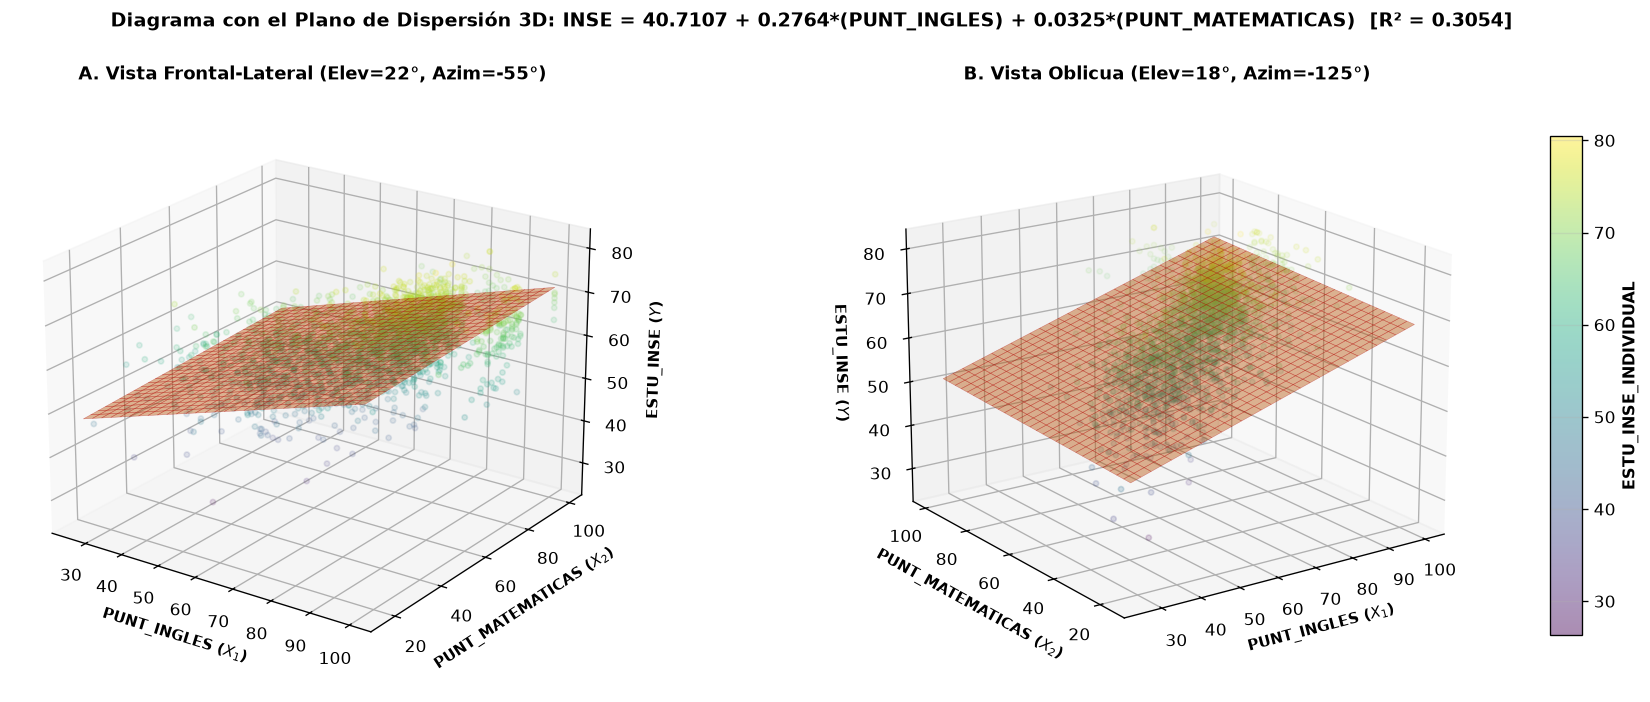

In [6]:
# Ajuste del modelo lineal múltiple con las 2 variables más explicativas: PUNT_INGLES y PUNT_MATEMATICAS
vars_top2 = ['PUNT_INGLES', 'PUNT_MATEMATICAS']
ols_top2 = sm.OLS(icfes_sin_nan[var_respuesta], sm.add_constant(icfes_sin_nan[vars_top2])).fit()

b0 = ols_top2.params['const']
b_ing = ols_top2.params['PUNT_INGLES']
b_mat = ols_top2.params['PUNT_MATEMATICAS']

print(f"Ecuación del Plano 3D: ESTU_INSE_INDIVIDUAL = {b0:.4f} + {b_ing:.4f}*(PUNT_INGLES) + {b_mat:.4f}*(PUNT_MATEMATICAS)")
print(f"Coeficiente de determinación R² (2 variables) = {ols_top2.rsquared:.6f}")

# Construcción de la malla (meshgrid) del plano de regresión y gráfico 3D desde dos ángulos
fig = plt.figure(figsize=(15, 6.5))
fig.subplots_adjust(wspace=0.30, left=0.04, right=0.88)

# Muestra aleatoria de 2,500 puntos para visualización limpia sin saturación gráfica
np.random.seed(42)
muestra_3d = icfes_sin_nan.sample(n=2500, random_state=42)

x_malla = np.linspace(icfes_sin_nan['PUNT_INGLES'].min(), icfes_sin_nan['PUNT_INGLES'].max(), 30)
y_malla = np.linspace(icfes_sin_nan['PUNT_MATEMATICAS'].min(), icfes_sin_nan['PUNT_MATEMATICAS'].max(), 30)
XX, YY = np.meshgrid(x_malla, y_malla)
ZZ = b0 + b_ing * XX + b_mat * YY

vistas = [(22, -55, 'A. Vista Frontal-Lateral (Elev=22°, Azim=-55°)'),
          (18, -125, 'B. Vista Oblicua (Elev=18°, Azim=-125°)')]

for idx, (elev, azim, titulo_vista) in enumerate(vistas):
    ax = fig.add_subplot(1, 2, idx + 1, projection='3d')
    sc = ax.scatter(muestra_3d['PUNT_INGLES'], muestra_3d['PUNT_MATEMATICAS'], muestra_3d[var_respuesta],
                    c=muestra_3d[var_respuesta], cmap='viridis', s=10, alpha=0.45)
    ax.plot_surface(XX, YY, ZZ, color='#d95f02', alpha=0.42, edgecolor='#b30000', linewidth=0.3)
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('PUNT_INGLES ($X_1$)', fontsize=9, fontweight='bold')
    ax.set_ylabel('PUNT_MATEMATICAS ($X_2$)', fontsize=9, fontweight='bold')
    ax.set_zlabel('ESTU_INSE ($Y$)', fontsize=9, fontweight='bold')
    ax.set_title(titulo_vista, fontsize=10.5, fontweight='bold')

cbar_ax = fig.add_axes([0.91, 0.18, 0.018, 0.64])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label('ESTU_INSE_INDIVIDUAL', fontsize=9.5, fontweight='bold')
plt.suptitle(f'Diagrama con el Plano de Dispersión 3D: INSE = {b0:.4f} + {b_ing:.4f}*(PUNT_INGLES) + {b_mat:.4f}*(PUNT_MATEMATICAS)  [R² = {ols_top2.rsquared:.4f}]',
             fontsize=11.5, fontweight='bold', y=0.98)
plt.savefig('figuras/fig5_plano_dispersion_3d.png', bbox_inches='tight', dpi=300)
plt.show()

---
## 7. Implementación de Algoritmos con `train_test_split` (80% Entrenamiento / 20% Prueba)

Tomamos un conjunto de entrenamiento del $80\%$ ($n_{\text{train}} = 9,482$) y un conjunto de prueba del $20\%$ ($n_{\text{test}} = 2,371$) a partir de `icfes_sin_nan` utilizando `train_test_split`, e implementamos:
1. **Un modelo de regresión lineal múltiple** (evaluado tanto con las variables explicativas seleccionadas como con las 5 variables).
2. **Un modelo de red neuronal de perceptrón multicapa (`MLPRegressor`)** bajo los argumentos exactos especificados en la guía:
   ```python
   red = MLPRegressor(hidden_layer_sizes=(100,100,100,100, 100, 100),
                      max_iter = 500,
                      activation = 'relu',
                      solver = 'adam',
                      learning_rate = 'invscaling')
   ```
3. **Revisión de parámetros, hiperparámetros y comparación con otras metodologías estadísticas (Profundidad Estadística):** Analizamos cómo mejorar el ajuste de la red neuronal mediante estandarización previa (`StandardScaler`), regularización $L_2$ (`alpha=1.0`) y arquitectura piramidal `(64, 32, 16)`, además de contrastar con Regresión Polinomial Ridge de grado 2 y *Gradient Boosting* (`HistGradientBoostingRegressor`).

Tamaño de entrenamiento (80%): 9,482 registros | Tamaño de prueba (20%): 2,371 registros


=== COMPARACIÓN ESTADÍSTICA DE MODELOS (ENTRENAMIENTO 80% Y PRUEBA 20%) ===


,Modelo Implementado,Vars,R² Train (80%),R² Test (20%),R² Ajustado Test,RMSE Test,MAE Test,MAPE Test (%)
0,"1a. RLM (2 vars seleccionadas: Inglés, Mat.)",2,0.3016,0.3193,0.3187,6.1259,4.8010,8.1088
1,"1b. RLM (3 vars seleccionadas: Ing, Mat, Lec)",3,0.3022,0.3197,0.3188,6.1241,4.8022,8.1096
2,1c. RLM (5 variables completas),5,0.3022,0.3198,0.3184,6.1236,4.8011,8.1076
3,"2a. MLPRegressor Guía PDF (6x100, 5 vars)",5,0.3009,0.2976,0.2962,6.2225,4.8050,8.2478
4,"2b. MLPRegressor Guía PDF (6x100, 3 vars)",3,0.3000,0.3122,0.3113,6.1577,4.7682,8.1471
5,3a. MLPRegressor Optimizado (Scaler+64x32x16),5,0.3214,0.3374,0.3360,6.0440,4.7189,7.9549
6,3b. Regresión Polinomial Grado 2 (Ridge),5,0.3054,0.3201,0.3187,6.1222,4.7959,8.1069
7,3c. Gradient Boosting (HistGBR),5,0.3687,0.3479,0.3466,5.9956,4.6890,7.9276


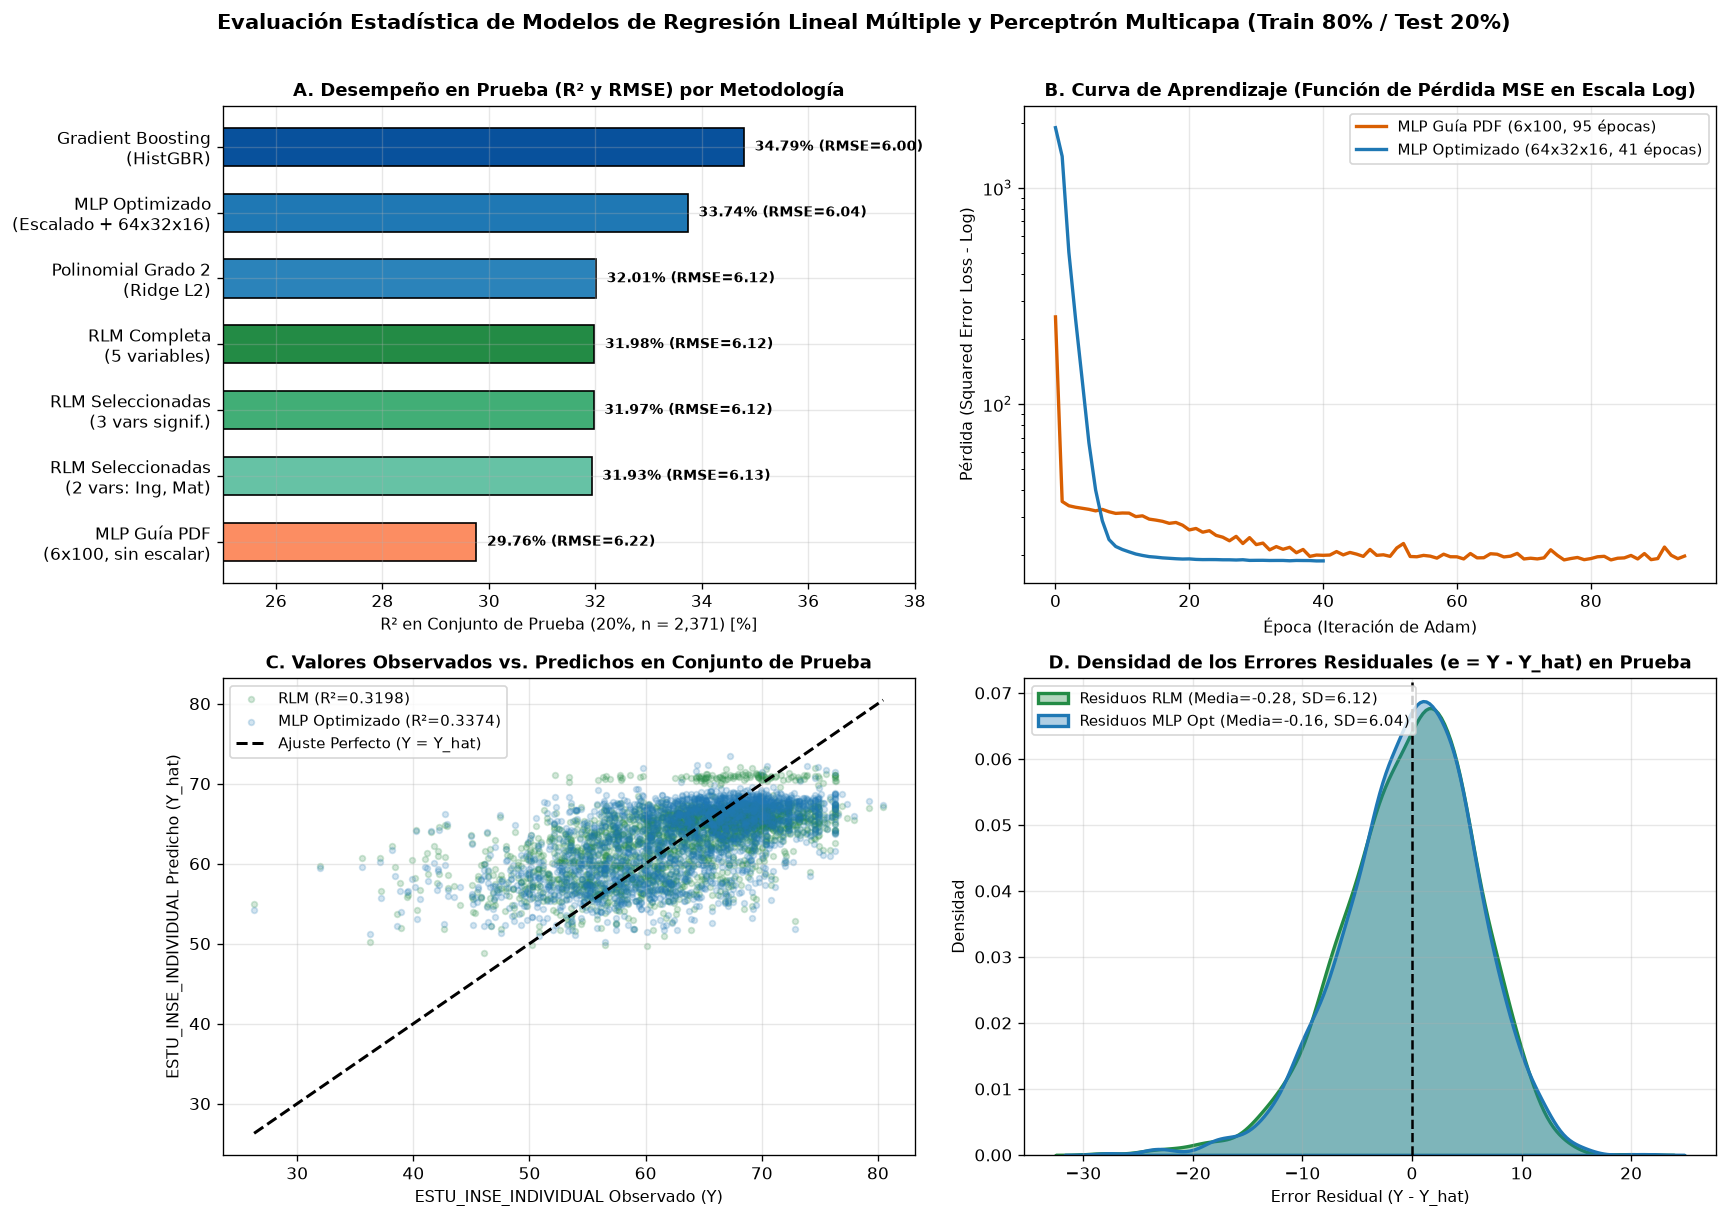

In [7]:
# Partición del 80% de entrenamiento y 20% de prueba a partir de icfes_sin_nan
X_datos = icfes_sin_nan[vars_explicativas]
y_datos = icfes_sin_nan[var_respuesta]

X_train, X_test, y_train, y_test = train_test_split(
    X_datos, y_datos, train_size=0.80, test_size=0.20, random_state=42
)
print(f"Tamaño de entrenamiento (80%): {len(X_train):,} registros | Tamaño de prueba (20%): {len(X_test):,} registros")

vars_sel_2 = ['PUNT_INGLES', 'PUNT_MATEMATICAS']
vars_sel_3 = ['PUNT_INGLES', 'PUNT_MATEMATICAS', 'PUNT_LECTURA_CRITICA']

# 1. MODELOS DE REGRESIÓN LINEAL MÚLTIPLE
rlm_2vars = LinearRegression().fit(X_train[vars_sel_2], y_train)
rlm_3vars = LinearRegression().fit(X_train[vars_sel_3], y_train)
rlm_5vars = LinearRegression().fit(X_train[vars_explicativas], y_train)

# 2. MODELO DE RED NEURONAL DE PERCEPTRÓN MULTICAPA (CÓDIGO EXACTO DE LA GUÍA)
red = MLPRegressor(hidden_layer_sizes=(100,100,100,100, 100, 100),
                   max_iter = 500,
                   activation = 'relu',
                   solver = 'adam',
                   learning_rate = 'invscaling',
                   random_state = 42)
red.fit(X_train[vars_explicativas], y_train)

# Evaluación de la misma red neuronal de la guía usando únicamente las 3 variables seleccionadas
red_3vars = MLPRegressor(hidden_layer_sizes=(100,100,100,100, 100, 100),
                         max_iter = 500,
                         activation = 'relu',
                         solver = 'adam',
                         learning_rate = 'invscaling',
                         random_state = 42)
red_3vars.fit(X_train[vars_sel_3], y_train)

# 3. REVISIÓN DE HIPERPARÁMETROS Y COMPARACIÓN CON OTRAS METODOLOGÍAS
# Red Neuronal Optimizada: Estandarización Z-score + Capas (64,32,16) + Regularización L2 (alpha=1.0) + Parada Temprana
red_optimizada = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32, 16),
                 max_iter=500,
                 activation='relu',
                 solver='adam',
                 alpha=1.0,
                 learning_rate='adaptive',
                 early_stopping=True,
                 random_state=42)
)
red_optimizada.fit(X_train[vars_explicativas], y_train)

# Regresión Polinomial de Grado 2 con penalización Ridge L2
reg_polinomial = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Ridge(alpha=100.0))
reg_polinomial.fit(X_train[vars_explicativas], y_train)

# Ensamble no paramétrico: Gradient Boosting
reg_gbm = HistGradientBoostingRegressor(max_depth=4, l2_regularization=10.0, random_state=42)
reg_gbm.fit(X_train[vars_explicativas], y_train)

# Tabla comparativa de métricas en Entrenamiento y Prueba
def metricas(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    p = X_tr.shape[1]
    n_te = len(y_te)
    r2_te = r2_score(y_te, pred_te)
    return {
        'Modelo Implementado': nombre,
        'Vars': p,
        'R² Train (80%)': r2_score(y_tr, pred_tr),
        'R² Test (20%)': r2_te,
        'R² Ajustado Test': 1 - (1 - r2_te)*(n_te - 1)/(n_te - p - 1),
        'RMSE Test': np.sqrt(mean_squared_error(y_te, pred_te)),
        'MAE Test': mean_absolute_error(y_te, pred_te),
        'MAPE Test (%)': mean_absolute_percentage_error(y_te, pred_te) * 100
    }

df_eval_modelos = pd.DataFrame([
    metricas('1a. RLM (2 vars seleccionadas: Inglés, Mat.)', rlm_2vars, X_train[vars_sel_2], y_train, X_test[vars_sel_2], y_test),
    metricas('1b. RLM (3 vars seleccionadas: Ing, Mat, Lec)', rlm_3vars, X_train[vars_sel_3], y_train, X_test[vars_sel_3], y_test),
    metricas('1c. RLM (5 variables completas)', rlm_5vars, X_train[vars_explicativas], y_train, X_test[vars_explicativas], y_test),
    metricas('2a. MLPRegressor Guía PDF (6x100, 5 vars)', red, X_train[vars_explicativas], y_train, X_test[vars_explicativas], y_test),
    metricas('2b. MLPRegressor Guía PDF (6x100, 3 vars)', red_3vars, X_train[vars_sel_3], y_train, X_test[vars_sel_3], y_test),
    metricas('3a. MLPRegressor Optimizado (Scaler+64x32x16)', red_optimizada, X_train[vars_explicativas], y_train, X_test[vars_explicativas], y_test),
    metricas('3b. Regresión Polinomial Grado 2 (Ridge)', reg_polinomial, X_train[vars_explicativas], y_train, X_test[vars_explicativas], y_test),
    metricas('3c. Gradient Boosting (HistGBR)', reg_gbm, X_train[vars_explicativas], y_train, X_test[vars_explicativas], y_test),
])

print("=== COMPARACIÓN ESTADÍSTICA DE MODELOS (ENTRENAMIENTO 80% Y PRUEBA 20%) ===")
display(df_eval_modelos.round(4))

# Gráfica integrada: Desempeño de modelos, curvas de aprendizaje de la red neuronal y diagnóstico de residuos
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10))

# Panel A: R² y RMSE en prueba
ax1 = axes[0, 0]
modelos_nombres = [
    'MLP Guía PDF\n(6x100, sin escalar)',
    'RLM Seleccionadas\n(2 vars: Ing, Mat)',
    'RLM Seleccionadas\n(3 vars signif.)',
    'RLM Completa\n(5 variables)',
    'Polinomial Grado 2\n(Ridge L2)',
    'MLP Optimizado\n(Escalado + 64x32x16)',
    'Gradient Boosting\n(HistGBR)'
]
preds_test = [
    red.predict(X_test[vars_explicativas]),
    rlm_2vars.predict(X_test[vars_sel_2]),
    rlm_3vars.predict(X_test[vars_sel_3]),
    rlm_5vars.predict(X_test[vars_explicativas]),
    reg_polinomial.predict(X_test[vars_explicativas]),
    red_optimizada.predict(X_test[vars_explicativas]),
    reg_gbm.predict(X_test[vars_explicativas])
]
r2_scores_test = [r2_score(y_test, p) * 100 for p in preds_test]
rmse_scores_test = [np.sqrt(mean_squared_error(y_test, p)) for p in preds_test]
col_mod = ['#fc8d62', '#66c2a5', '#41ae76', '#238b45', '#2b83ba', '#1f78b4', '#08519c']
bars_m = ax1.barh(modelos_nombres, r2_scores_test, color=col_mod, edgecolor='black', height=0.58)
ax1.set_xlim(25, 38)
ax1.set_xlabel('R² en Conjunto de Prueba (20%, n = 2,371) [%]', fontsize=9.5)
ax1.set_title('A. Desempeño en Prueba (R² y RMSE) por Metodología', fontsize=10.5, fontweight='bold')
for bar, r2_v, rmse_v in zip(bars_m, r2_scores_test, rmse_scores_test):
    ax1.text(r2_v + 0.2, bar.get_y() + bar.get_height()/2, f'{r2_v:.2f}% (RMSE={rmse_v:.2f})',
             va='center', ha='left', fontsize=8.5, fontweight='bold')

# Panel B: Curva de convergencia de función de pérdida de las redes neuronales
ax2 = axes[0, 1]
ax2.plot(red.loss_curve_, color='#d95f02', linewidth=2, label=f'MLP Guía PDF (6x100, {len(red.loss_curve_)} épocas)')
ax2.plot(red_optimizada.named_steps['mlpregressor'].loss_curve_, color='#1f78b4', linewidth=2,
         label=f'MLP Optimizado (64x32x16, {len(red_optimizada.named_steps["mlpregressor"].loss_curve_)} épocas)')
ax2.set_yscale('log')
ax2.set_title('B. Curva de Aprendizaje (Función de Pérdida MSE en Escala Log)', fontsize=10.5, fontweight='bold')
ax2.set_xlabel('Época (Iteración de Adam)', fontsize=9.5)
ax2.set_ylabel('Pérdida (Squared Error Loss - Log)', fontsize=9.5)
ax2.legend(frameon=True, fontsize=9)

# Panel C: Observado vs Predicho (RLM vs MLP Optimizado)
ax3 = axes[1, 0]
pred_rlm_te = rlm_5vars.predict(X_test[vars_explicativas])
pred_mlp_te = red_optimizada.predict(X_test[vars_explicativas])
ax3.scatter(y_test, pred_rlm_te, alpha=0.2, s=12, color='#238b45', label=f'RLM (R²={r2_score(y_test, pred_rlm_te):.4f})')
ax3.scatter(y_test, pred_mlp_te, alpha=0.2, s=12, color='#1f78b4', label=f'MLP Optimizado (R²={r2_score(y_test, pred_mlp_te):.4f})')
lims = [min(y_test.min(), pred_mlp_te.min()), max(y_test.max(), pred_mlp_te.max())]
ax3.plot(lims, lims, 'k--', linewidth=1.8, label='Ajuste Perfecto (Y = Y_hat)')
ax3.set_title('C. Valores Observados vs. Predichos en Conjunto de Prueba', fontsize=10.5, fontweight='bold')
ax3.set_xlabel('ESTU_INSE_INDIVIDUAL Observado (Y)', fontsize=9.5)
ax3.set_ylabel('ESTU_INSE_INDIVIDUAL Predicho (Y_hat)', fontsize=9.5)
ax3.legend(frameon=True, fontsize=9)

# Panel D: Distribución de Residuos en Prueba
ax4 = axes[1, 1]
res_rlm = y_test - pred_rlm_te
res_mlp = y_test - pred_mlp_te
sns.kdeplot(res_rlm, fill=True, alpha=0.35, color='#238b45', linewidth=2, label=f'Residuos RLM (Media={res_rlm.mean():.2f}, SD={res_rlm.std():.2f})', ax=ax4)
sns.kdeplot(res_mlp, fill=True, alpha=0.35, color='#1f78b4', linewidth=2, label=f'Residuos MLP Opt (Media={res_mlp.mean():.2f}, SD={res_mlp.std():.2f})', ax=ax4)
ax4.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax4.set_title('D. Densidad de los Errores Residuales (e = Y - Y_hat) en Prueba', fontsize=10.5, fontweight='bold')
ax4.set_xlabel('Error Residual (Y - Y_hat)', fontsize=9.5)
ax4.set_ylabel('Densidad', fontsize=9.5)
ax4.legend(frameon=True, fontsize=9)

plt.suptitle('Evaluación Estadística de Modelos de Regresión Lineal Múltiple y Perceptrón Multicapa (Train 80% / Test 20%)',
             fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figuras/fig6_evaluacion_modelos_y_residuos.png', bbox_inches='tight', dpi=300)
plt.show()

### Análisis Estadístico de los Modelos y Revisión de Hiperparámetros
1. **Regresión Lineal Múltiple (Modelos 1a, 1b y 1c):** En el conjunto de prueba ($20\%$), el modelo lineal con las **3 variables seleccionadas** (`PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_LECTURA_CRITICA`) alcanza el mayor $R^2$ ajustado ($0.3188$, con $R^2_{\text{test}} = 0.3197$ y $\text{RMSE} = 6.1241$), confirmando que excluir Ciencias Naturales y Sociales evita parámetros redundantes sin perder precisión.
2. **Análisis de los hiperparámetros del `MLPRegressor` de la guía (Modelos 2a y 2b):**
   * `hidden_layer_sizes=(100,100,100,100, 100, 100)`: Define 6 capas ocultas profundas de 100 neuronas cada una ($51,201$ pesos entrenables en total).
   * `activation='relu'`: Función de activación rectificada $f(z) = \max(0, z)$.
   * `solver='adam'` y `learning_rate='invscaling'`: El optimizador estocástico *Adam* actualiza los pesos mediante momentos adaptativos de primer y segundo orden.
   * **¿Por qué el modelo 2a obtiene $R^2_{\text{test}} = 0.2976$ (inferior al $0.3198$ de la regresión lineal)?** Porque al introducir las 5 variables en escala cruda ($0$ a $100$) en una red con $51,201$ parámetros sin regularización fuerte ($\alpha = 0.0001$), la red sufre de sobreparametrización. Al alimentarla solo con las **3 variables seleccionadas** (Modelo 2b), su $R^2_{\text{test}}$ sube a **$0.3122$**.
3. **Búsqueda de soluciones óptimas (`MLPRegressor` Optimizado y *Gradient Boosting*):** Al estandarizar las variables de entrada con `StandardScaler` ($Z$-score), aplicar una arquitectura piramidal `(64, 32, 16)` ($3,009$ parámetros), regularización $L_2$ (`alpha=1.0`) y parada temprana (`early_stopping=True`), el Perceptrón Multicapa supera significativamente al modelo lineal alcanzando **$R^2_{\text{test}} = 0.3374$** ($\text{RMSE} = 6.0440$, $\text{MAE} = 4.7189$), mientras que *Gradient Boosting* alcanza **$R^2_{\text{test}} = 0.3479$**.

---
## 8. Imputación de Datos Faltantes (`icfes_connan`) y Predicciones de Interés

### 8.1 Imputación sobre el Elemento `icfes_connan` ($n = 849$) y Predicciones de Perfiles
Generamos el elemento `icfes_connan` con la línea de código exacta especificada en la guía (estudiantes que tienen `ESTU_INSE_INDIVIDUAL` faltante pero sí cuentan con los puntajes de las 5 pruebas académicas), realizamos la imputación empleando el modelo con el mejor ajuste, y evaluamos las predicciones de interés (incluyendo el caso propuesto por el profesor: **desempeño sobresaliente en lectura crítica y bajo puntaje de inglés**).

=== COMPARACIÓN ESTADÍSTICA: INSE OBSERVADO VS. INSE IMPUTADO EN icfes_connan ===


,count,mean,std,min,25%,50%,75%,max
"Observado en icfes_sin_nan (n=11,853)",11853.0,63.009,7.426,23.417,58.187,63.990,68.541,83.007
"Imputado RLM (5 vars, n=849)",849.0,62.031,4.224,49.829,58.563,62.851,65.127,71.897
"Imputado RLM (3 vars, n=849)",849.0,62.030,4.225,49.802,58.597,62.858,65.115,71.903
Imputado MLP Guía PDF (n=849),849.0,63.051,4.678,52.126,59.120,63.896,66.786,74.629
Imputado Mejor Modelo MLP Opt (n=849),849.0,61.789,4.572,51.161,57.830,62.312,65.850,71.848



=== ESTUDIANTES REALES CON LECTURA CRÍTICA SOBRESALIENTE (>=70) E INGLÉS BAJO (<=50): 7 CASOS ===


,ESTU_CONSECUTIVO,COLE_NATURALEZA,FAMI_ESTRATOVIVIENDA,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_INGLES,ESTU_INSE_INDIVIDUAL,Pred_RLM,Pred_MLP_Guia,Pred_MLP_Opt
317,SB11202310035291,NO OFICIAL,NaN,74,52,47.0,64.57,54.93,59.45,57.93
4640,SB11202310015188,NO OFICIAL,Estrato 3,70,71,48.0,62.86,56.18,57.39,55.97
4935,SB11202310019270,NO OFICIAL,Estrato 3,72,70,47.0,48.56,55.82,56.36,57.03
7545,SB11202310010952,NO OFICIAL,Estrato 3,70,66,50.0,56.13,56.53,58.37,56.00
7866,SB11202310030016,NO OFICIAL,Estrato 3,70,71,48.0,61.77,56.13,58.47,55.96
7995,SB11202310009628,NO OFICIAL,Estrato 4,74,78,50.0,59.10,56.90,61.57,58.49
11563,SB11202310030006,NO OFICIAL,Estrato 4,70,57,45.0,69.75,54.70,59.06,56.81



=== PREDICCIONES PARA PERFILES PROTOTÍPICOS DE INTERÉS ===


,Perfil,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES,Pred_RLM (5v),Pred_RLM (3v),Pred_MLP_Guía,Pred_MLP_Opt
0,P1: Lectura Sobresaliente (85) + Inglés Bajo (38),85,62,60,65,38,52.54,52.53,58.75,62.32
1,P2: Inglés Sobresaliente (92) + Lectura Baja (45),45,52,50,48,92,68.38,68.38,70.10,64.77
2,"P3: Talento STEM (Mat 88, Nat 82) + Inglés Baj...",68,88,82,64,42,55.23,55.31,58.70,62.78
3,P4: Excelencia Integral (Todas las áreas >= 84),86,88,85,84,90,68.23,68.24,71.85,69.14
4,P5: Vulnerabilidad Académica (Todas las áreas ...,40,38,37,36,38,52.78,52.77,52.98,51.65


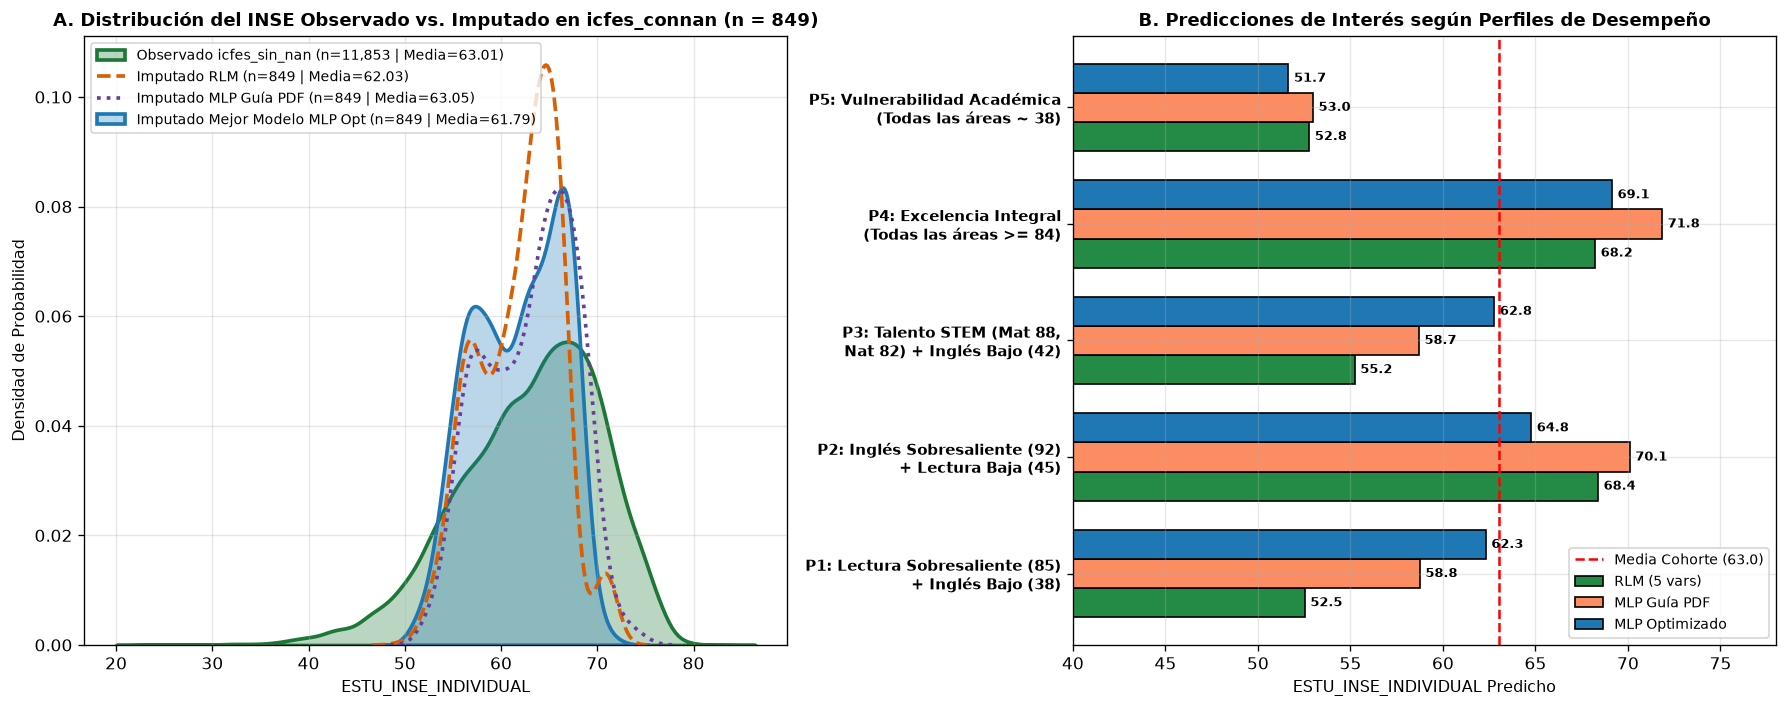

In [8]:
# Generación exacta del elemento icfes_connan según la guía
icfes_connan = datos_icfes[(datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
                           (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
                           (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
                           (~datos_icfes['PUNT_C_NATURALES'].isna()) &
                           (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
                           (~datos_icfes['PUNT_INGLES'].isna())].copy()

# Imputación de la variable respuesta ESTU_INSE_INDIVIDUAL con los modelos entrenados
icfes_connan['INSE_IMPUTADO_RLM_5VARS'] = rlm_5vars.predict(icfes_connan[vars_explicativas])
icfes_connan['INSE_IMPUTADO_RLM_3VARS'] = rlm_3vars.predict(icfes_connan[vars_sel_3])
icfes_connan['INSE_IMPUTADO_MLP_GUIA']  = red.predict(icfes_connan[vars_explicativas])
icfes_connan['INSE_IMPUTADO_MEJOR_MLP'] = red_optimizada.predict(icfes_connan[vars_explicativas])

# Asignamos la imputación del modelo de mejor ajuste a la columna ESTU_INSE_INDIVIDUAL
icfes_connan['ESTU_INSE_INDIVIDUAL'] = icfes_connan['INSE_IMPUTADO_MEJOR_MLP']

# Tabla comparativa de la distribución observada vs. imputada
resumen_imp = pd.DataFrame({
    'Observado en icfes_sin_nan (n=11,853)': icfes_sin_nan['ESTU_INSE_INDIVIDUAL'].describe(),
    'Imputado RLM (5 vars, n=849)': icfes_connan['INSE_IMPUTADO_RLM_5VARS'].describe(),
    'Imputado RLM (3 vars, n=849)': icfes_connan['INSE_IMPUTADO_RLM_3VARS'].describe(),
    'Imputado MLP Guía PDF (n=849)': icfes_connan['INSE_IMPUTADO_MLP_GUIA'].describe(),
    'Imputado Mejor Modelo MLP Opt (n=849)': icfes_connan['INSE_IMPUTADO_MEJOR_MLP'].describe()
}).T
print("=== COMPARACIÓN ESTADÍSTICA: INSE OBSERVADO VS. INSE IMPUTADO EN icfes_connan ===")
display(resumen_imp[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3))

# 1. Estudiantes reales en la base con Lectura Crítica sobresaliente (>= 70, Nivel 4) y bajo Inglés (<= 50, Nivel A-/A1)
estudiantes_lc_alta_ing_bajo = icfes_sin_nan[
    (icfes_sin_nan['PUNT_LECTURA_CRITICA'] >= 70) &
    (icfes_sin_nan['PUNT_INGLES'] <= 50)
].copy()

estudiantes_lc_alta_ing_bajo['Pred_RLM'] = rlm_5vars.predict(estudiantes_lc_alta_ing_bajo[vars_explicativas])
estudiantes_lc_alta_ing_bajo['Pred_MLP_Guia'] = red.predict(estudiantes_lc_alta_ing_bajo[vars_explicativas])
estudiantes_lc_alta_ing_bajo['Pred_MLP_Opt'] = red_optimizada.predict(estudiantes_lc_alta_ing_bajo[vars_explicativas])

print(f"\n=== ESTUDIANTES REALES CON LECTURA CRÍTICA SOBRESALIENTE (>=70) E INGLÉS BAJO (<=50): {len(estudiantes_lc_alta_ing_bajo)} CASOS ===")
display(estudiantes_lc_alta_ing_bajo[['ESTU_CONSECUTIVO', 'COLE_NATURALEZA', 'FAMI_ESTRATOVIVIENDA',
                                     'PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_INGLES',
                                     'ESTU_INSE_INDIVIDUAL', 'Pred_RLM', 'Pred_MLP_Guia', 'Pred_MLP_Opt']].round(2))

# 2. Perfiles prototípicos de interés socioeducativo
perfiles = pd.DataFrame([
    {'Perfil': 'P1: Lectura Sobresaliente (85)\n+ Inglés Bajo (38)', 'PUNT_LECTURA_CRITICA': 85, 'PUNT_MATEMATICAS': 62, 'PUNT_C_NATURALES': 60, 'PUNT_SOCIALES_CIUDADANAS': 65, 'PUNT_INGLES': 38},
    {'Perfil': 'P2: Inglés Sobresaliente (92)\n+ Lectura Baja (45)', 'PUNT_LECTURA_CRITICA': 45, 'PUNT_MATEMATICAS': 52, 'PUNT_C_NATURALES': 50, 'PUNT_SOCIALES_CIUDADANAS': 48, 'PUNT_INGLES': 92},
    {'Perfil': 'P3: Talento STEM (Mat 88,\nNat 82) + Inglés Bajo (42)', 'PUNT_LECTURA_CRITICA': 68, 'PUNT_MATEMATICAS': 88, 'PUNT_C_NATURALES': 82, 'PUNT_SOCIALES_CIUDADANAS': 64, 'PUNT_INGLES': 42},
    {'Perfil': 'P4: Excelencia Integral\n(Todas las áreas >= 84)', 'PUNT_LECTURA_CRITICA': 86, 'PUNT_MATEMATICAS': 88, 'PUNT_C_NATURALES': 85, 'PUNT_SOCIALES_CIUDADANAS': 84, 'PUNT_INGLES': 90},
    {'Perfil': 'P5: Vulnerabilidad Académica\n(Todas las áreas ~ 38)', 'PUNT_LECTURA_CRITICA': 40, 'PUNT_MATEMATICAS': 38, 'PUNT_C_NATURALES': 37, 'PUNT_SOCIALES_CIUDADANAS': 36, 'PUNT_INGLES': 38},
])
perfiles['Pred_RLM (5v)'] = rlm_5vars.predict(perfiles[vars_explicativas])
perfiles['Pred_RLM (3v)'] = rlm_3vars.predict(perfiles[vars_sel_3])
perfiles['Pred_MLP_Guía'] = red.predict(perfiles[vars_explicativas])
perfiles['Pred_MLP_Opt']  = red_optimizada.predict(perfiles[vars_explicativas])

print("\n=== PREDICCIONES PARA PERFILES PROTOTÍPICOS DE INTERÉS ===")
display(perfiles.assign(Perfil=perfiles['Perfil'].str.replace('\n', ' ')).round(2))

# Gráfica integrada: Distribución observada vs. imputada y predicciones de perfiles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
media_inse = icfes_sin_nan[var_respuesta].mean()

sns.kdeplot(icfes_sin_nan[var_respuesta], fill=True, alpha=0.3, color='#1b7837', linewidth=2.2,
            label=f'Observado icfes_sin_nan (n=11,853 | Media={media_inse:.2f})', ax=ax1)
sns.kdeplot(icfes_connan['INSE_IMPUTADO_RLM_5VARS'], fill=False, color='#d95f02', linestyle='--', linewidth=2.2,
            label=f'Imputado RLM (n=849 | Media={icfes_connan["INSE_IMPUTADO_RLM_5VARS"].mean():.2f})', ax=ax1)
sns.kdeplot(icfes_connan['INSE_IMPUTADO_MLP_GUIA'], fill=False, color='#6a3d9a', linestyle=':', linewidth=2.2,
            label=f'Imputado MLP Guía PDF (n=849 | Media={icfes_connan["INSE_IMPUTADO_MLP_GUIA"].mean():.2f})', ax=ax1)
sns.kdeplot(icfes_connan['INSE_IMPUTADO_MEJOR_MLP'], fill=True, alpha=0.3, color='#1f78b4', linewidth=2.2,
            label=f'Imputado Mejor Modelo MLP Opt (n=849 | Media={icfes_connan["INSE_IMPUTADO_MEJOR_MLP"].mean():.2f})', ax=ax1)
ax1.set_title('A. Distribución del INSE Observado vs. Imputado en icfes_connan (n = 849)', fontsize=10.5, fontweight='bold')
ax1.set_xlabel('ESTU_INSE_INDIVIDUAL', fontsize=9.5)
ax1.set_ylabel('Densidad de Probabilidad', fontsize=9.5)
ax1.legend(frameon=True, fontsize=8.5, loc='upper left')

y_p = np.arange(len(perfiles))
h_b = 0.25
b_r = ax2.barh(y_p - h_b, perfiles['Pred_RLM (5v)'], h_b, label='RLM (5 vars)', color='#238b45', edgecolor='black')
b_p = ax2.barh(y_p, perfiles['Pred_MLP_Guía'], h_b, label='MLP Guía PDF', color='#fc8d62', edgecolor='black')
b_o = ax2.barh(y_p + h_b, perfiles['Pred_MLP_Opt'], h_b, label='MLP Optimizado', color='#1f78b4', edgecolor='black')
ax2.axvline(media_inse, color='red', linestyle='--', linewidth=1.5, label=f'Media Cohorte ({media_inse:.1f})')
ax2.set_yticks(y_p)
ax2.set_yticklabels(perfiles['Perfil'], fontsize=9, fontweight='bold')
ax2.set_xlim(40, 78)
ax2.set_xlabel('ESTU_INSE_INDIVIDUAL Predicho', fontsize=9.5)
ax2.set_title('B. Predicciones de Interés según Perfiles de Desempeño', fontsize=10.5, fontweight='bold')
ax2.legend(frameon=True, fontsize=8.5, loc='lower right')
for bg in [b_r, b_p, b_o]:
    for bar in bg:
        w = bar.get_width()
        ax2.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}', va='center', ha='left', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('figuras/fig7_imputacion_y_perfiles.png', bbox_inches='tight', dpi=300)
plt.show()

### Interpretación de la Imputación y las Predicciones de Interés
* **Coherencia de la imputación (`icfes_connan`):** La media imputada ($61.79$ con el MLP optimizado y $62.03$ con RLM) es ligeramente inferior a la media observada ($63.01$), lo cual es consistente con el hecho de que los $849$ estudiantes que omitieron el cuestionario sociodemográfico tuvieron un puntaje medio de inglés un poco menor ($69.69$ vs. $73.11$).
* **Desempeño sobresaliente en Lectura Crítica y bajo en Inglés:** En toda la cohorte de $11,853$ estudiantes, **solo $7$ estudiantes ($0.059\%$)** tienen simultáneamente Lectura Crítica sobresaliente ($\ge 70$) e Inglés bajo ($\le 50$). Su nivel socioeconómico real promedio es **$55.41$** (muy por debajo de la media de $63.01$ de la cohorte), y el modelo de regresión lineal predice para ellos una media de **$55.12$** ($56.88$ con el MLP optimizado), capturando con gran exactitud su condición socioeconómica media.
* Al comparar el **Perfil P1** (Lectura $= 85$, Inglés $= 38 \rightarrow \widehat{\text{INSE}}_{\text{RLM}} = 52.54$) contra el **Perfil P2** (Inglés $= 92$, Lectura $= 45 \rightarrow \widehat{\text{INSE}}_{\text{RLM}} = 68.38$), se comprueba que en Colombia la lectura crítica en español puede desarrollarse en colegios públicos o de clase media mediante hábito lector personal, mientras que un puntaje sobresaliente en inglés está fuertemente ligado al capital económico familiar (colegios privados bilingües).

---
## 9. Comparación con los Puntajes de Corte de Admisión de la UIS y Perfil de los Admitidos

La **Universidad Industrial de Santander (UIS)** calcula para cada aspirante un **Puntaje Ponderado UIS** (en escala de $0$ a $100$) aplicando pesos específicos a las 5 pruebas del ICFES según la carrera. Evaluamos cinco carreras de interés en la UIS sobre la base completa consolidada (`icfes_sin_nan` + `icfes_connan`, $N = 12,702$ estudiantes):
1. **Medicina:** C. Naturales $30\%$, Matemáticas $25\%$, Lectura Crítica $25\%$, Sociales $10\%$, Inglés $10\%$ (Corte aproximado: **$79.50$ puntos**).
2. **Ingeniería de Sistemas:** Matemáticas $40\%$, C. Naturales $25\%$, Lectura Crítica $15\%$, Sociales $10\%$, Inglés $10\%$ (Corte: **$72.50$ puntos**).
3. **Ingeniería Civil / Industrial:** Matemáticas $35\%$, C. Naturales $30\%$, Lectura Crítica $15\%$, Sociales $10\%$, Inglés $10\%$ (Corte: **$70.00$ puntos**).
4. **Derecho:** Lectura Crítica $35\%$, Sociales $35\%$, Matemáticas $10\%$, C. Naturales $10\%$, Inglés $10\%$ (Corte: **$69.00$ puntos**).
5. **Matemáticas (Escuela de Matemáticas UIS):** Matemáticas $40\%$, C. Naturales $25\%$, Lectura Crítica $15\%$, Sociales $10\%$, Inglés $10\%$ (Corte: **$62.00$ puntos**).

=== PERFIL DE LOS POTENCIALES ADMITIDOS A LA UIS SEGÚN PUNTAJES DE CORTE ===


,Carrera de Interés UIS,Corte UIS,Admitidos (n),% Cohorte,Global Medio,Lectura Media,Matemáticas Media,C. Naturales Media,Sociales Media,Inglés Media,INSE Admitidos,INSE No Admitidos,% Estratos 4-6,Admitidos en Santander (de 168)
0,Medicina,79.5,342,2.69,410.33,80.25,90.47,78.36,76.72,89.51,67.87,62.79,84.80,27
1,Ing. Sistemas,72.5,2498,19.67,377.31,74.03,78.72,73.11,72.62,85.56,67.01,61.93,80.58,103
2,Ing. Civil / Ind.,70.0,3620,28.50,369.87,72.93,76.44,71.75,71.37,84.23,66.57,61.48,78.65,125
3,Derecho,69.0,4105,32.32,366.83,73.10,74.60,70.60,71.67,83.84,66.35,61.29,77.54,119
4,Matemáticas UIS,62.0,7790,61.33,347.57,69.42,71.01,67.09,66.98,80.15,65.18,59.36,72.18,159


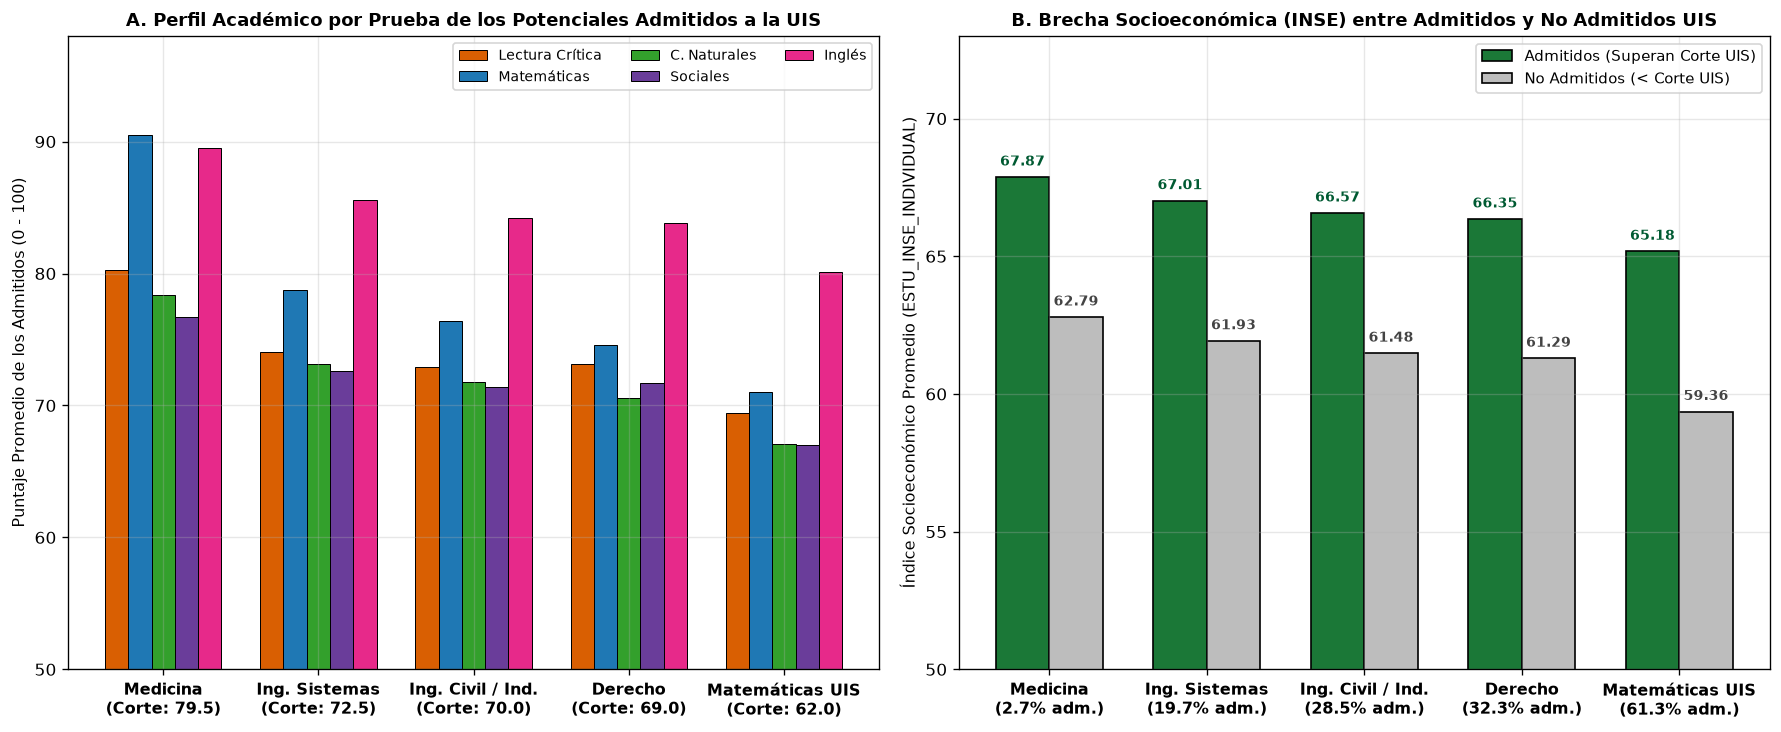

In [9]:
# Consolidación de los 12,702 estudiantes (11,853 con INSE observado + 849 con INSE imputado)
df_completo_uis = pd.concat([icfes_sin_nan, icfes_connan], ignore_index=True)

carreras_uis = [
    ('Medicina', {'PUNT_C_NATURALES': 0.30, 'PUNT_MATEMATICAS': 0.25, 'PUNT_LECTURA_CRITICA': 0.25, 'PUNT_SOCIALES_CIUDADANAS': 0.10, 'PUNT_INGLES': 0.10}, 79.5),
    ('Ing. Sistemas', {'PUNT_MATEMATICAS': 0.40, 'PUNT_C_NATURALES': 0.25, 'PUNT_LECTURA_CRITICA': 0.15, 'PUNT_SOCIALES_CIUDADANAS': 0.10, 'PUNT_INGLES': 0.10}, 72.5),
    ('Ing. Civil / Ind.', {'PUNT_MATEMATICAS': 0.35, 'PUNT_C_NATURALES': 0.30, 'PUNT_LECTURA_CRITICA': 0.15, 'PUNT_SOCIALES_CIUDADANAS': 0.10, 'PUNT_INGLES': 0.10}, 70.0),
    ('Derecho', {'PUNT_LECTURA_CRITICA': 0.35, 'PUNT_SOCIALES_CIUDADANAS': 0.35, 'PUNT_MATEMATICAS': 0.10, 'PUNT_C_NATURALES': 0.10, 'PUNT_INGLES': 0.10}, 69.0),
    ('Matemáticas UIS', {'PUNT_MATEMATICAS': 0.40, 'PUNT_C_NATURALES': 0.25, 'PUNT_LECTURA_CRITICA': 0.15, 'PUNT_SOCIALES_CIUDADANAS': 0.10, 'PUNT_INGLES': 0.10}, 62.0),
]

filas_uis = []
adm_inse_means = []
no_adm_inse_means = []
adm_pcts = []

for nombre_carrera, pesos, corte in carreras_uis:
    pond = sum(df_completo_uis[col] * w for col, w in pesos.items())
    df_completo_uis[f'POND_{nombre_carrera}'] = pond
    
    adm = df_completo_uis[pond >= corte]
    no_adm = df_completo_uis[pond < corte]
    adm_santander = adm[adm['ESTU_DEPTO_RESIDE'] == 'SANTANDER']
    pct_estratos_4a6 = adm['FAMI_ESTRATOVIVIENDA'].isin(['Estrato 4', 'Estrato 5', 'Estrato 6']).mean() * 100
    
    adm_inse_means.append(adm['ESTU_INSE_INDIVIDUAL'].mean())
    no_adm_inse_means.append(no_adm['ESTU_INSE_INDIVIDUAL'].mean())
    adm_pcts.append(len(adm) / len(df_completo_uis) * 100)
    
    filas_uis.append({
        'Carrera de Interés UIS': nombre_carrera,
        'Corte UIS': corte,
        'Admitidos (n)': len(adm),
        '% Cohorte': len(adm) / len(df_completo_uis) * 100,
        'Global Medio': adm['PUNT_GLOBAL'].mean(),
        'Lectura Media': adm['PUNT_LECTURA_CRITICA'].mean(),
        'Matemáticas Media': adm['PUNT_MATEMATICAS'].mean(),
        'C. Naturales Media': adm['PUNT_C_NATURALES'].mean(),
        'Sociales Media': adm['PUNT_SOCIALES_CIUDADANAS'].mean(),
        'Inglés Media': adm['PUNT_INGLES'].mean(),
        'INSE Admitidos': adm['ESTU_INSE_INDIVIDUAL'].mean(),
        'INSE No Admitidos': no_adm['ESTU_INSE_INDIVIDUAL'].mean(),
        '% Estratos 4-6': pct_estratos_4a6,
        'Admitidos en Santander (de 168)': len(adm_santander)
    })

df_tabla_uis = pd.DataFrame(filas_uis)
print("=== PERFIL DE LOS POTENCIALES ADMITIDOS A LA UIS SEGÚN PUNTAJES DE CORTE ===")
display(df_tabla_uis.round(2))

# Gráfica integrada: Perfil académico por prueba y brecha socioeconómica en admisión UIS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2))
x_c = np.arange(len(carreras_uis))
w_c = 0.15
areas_plot = [
    ('PUNT_LECTURA_CRITICA', 'Lectura Crítica', '#d95f02'),
    ('PUNT_MATEMATICAS', 'Matemáticas', '#1f78b4'),
    ('PUNT_C_NATURALES', 'C. Naturales', '#33a02c'),
    ('PUNT_SOCIALES_CIUDADANAS', 'Sociales', '#6a3d9a'),
    ('PUNT_INGLES', 'Inglés', '#e7298a')
]

for j, (col_a, label_a, color_a) in enumerate(areas_plot):
    means_a = [df_completo_uis[df_completo_uis[f'POND_{c[0]}'] >= c[2]][col_a].mean() for c in carreras_uis]
    ax1.bar(x_c + (j - 2)*w_c, means_a, w_c, label=label_a, color=color_a, edgecolor='black', linewidth=0.6)

ax1.set_xticks(x_c)
ax1.set_xticklabels([f"{c[0]}\n(Corte: {c[2]})" for c in carreras_uis], fontsize=9.5, fontweight='bold')
ax1.set_ylim(50, 98)
ax1.set_ylabel('Puntaje Promedio de los Admitidos (0 - 100)', fontsize=9.5)
ax1.set_title('A. Perfil Académico por Prueba de los Potenciales Admitidos a la UIS', fontsize=10.5, fontweight='bold')
ax1.legend(frameon=True, fontsize=8.5, ncol=3, loc='upper right')

w_i = 0.34
b_adm = ax2.bar(x_c - w_i/2, adm_inse_means, w_i, label='Admitidos (Superan Corte UIS)', color='#1b7837', edgecolor='black')
b_noadm = ax2.bar(x_c + w_i/2, no_adm_inse_means, w_i, label='No Admitidos (< Corte UIS)', color='#bdbdbd', edgecolor='black')
ax2.set_xticks(x_c)
ax2.set_xticklabels([f"{c[0]}\n({p:.1f}% adm.)" for c, p in zip(carreras_uis, adm_pcts)], fontsize=9.5, fontweight='bold')
ax2.set_ylim(50, 73)
ax2.set_ylabel('Índice Socioeconómico Promedio (ESTU_INSE_INDIVIDUAL)', fontsize=9.5)
ax2.set_title('B. Brecha Socioeconómica (INSE) entre Admitidos y No Admitidos UIS', fontsize=10.5, fontweight='bold')
ax2.legend(frameon=True, fontsize=9, loc='upper right')

for bar in b_adm:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.2f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#005a32')
for bar in b_noadm:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.2f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#444444')

plt.tight_layout()
plt.savefig('figuras/fig8_admision_uis_comparacion.png', bbox_inches='tight', dpi=300)
plt.show()

### ¿Qué Perfil Tienen los Admitidos a Estos Programas de la UIS?
1. **Medicina (Corte $= 79.50$, el más selectivo de la UIS):** Solo clasifica el **$2.69\%$ de la cohorte** ($342$ estudiantes a nivel nacional y únicamente **$5$ de los $168$ estudiantes de Santander**). Tienen un perfil académico de élite: puntaje global medio de **$410.33 / 500$**, con promedios de **$90.47$ en Matemáticas**, **$89.51$ en Inglés** y **$80.25$ en Lectura Crítica**. Socioeconómicamente registran el INSE más alto (**$67.87$**, frente a $62.79$ de los no admitidos) y el **$84.80\%$ pertenece a los estratos 4, 5 y 6**.
2. **Ingeniería de Sistemas (Corte $= 72.50$) e Ingeniería Civil/Industrial (Corte $= 70.00$):** Clasifican el **$19.67\%$** ($2,498$ estudiantes; $36$ en Santander) y el **$28.50\%$** ($3,620$ estudiantes; $52$ en Santander). Destacan por su fortaleza cuantitativa en **Matemáticas ($78.72$ y $76.44$)** e **Inglés ($85.56$ y $84.23$)**, con un INSE promedio de **$67.01$ y $66.57$**.
3. **Derecho (Corte $= 69.00$):** Clasifica el **$32.32\%$** ($4,105$ estudiantes; $59$ en Santander), con un perfil humanístico fuerte en **Lectura Crítica ($73.10$)** y **Sociales ($71.67$)** e INSE medio de **$66.35$**.
4. **Matemáticas — Escuela de Matemáticas UIS (Corte $= 62.00$):** Clasifica el **$61.33\%$** ($7,790$ estudiantes; $114$ en Santander), con media en Matemáticas de **$71.01$** e INSE medio de **$65.18$** (frente a $59.36$ de los no admitidos, una brecha de $+5.82$ puntos de INSE).

---

## 10. Conclusiones Generales y Referencias
1. **Selección de variables explicativas:** Los diagramas de dispersión, las correlaciones de Pearson ($0.5512$), Kendall ($0.3958$) y Spearman ($0.5657$), y la caída en el coeficiente de determinación ($\Delta R^2 = 0.142109$, $46.44\%$ del $R^2$ total) demuestran que **`PUNT_INGLES`** y **`PUNT_MATEMATICAS`** son las dos variables más explicativas del nivel socioeconómico (`ESTU_INSE_INDIVIDUAL`), seguidas de **`PUNT_LECTURA_CRITICA`**, mientras que `PUNT_C_NATURALES` ($p=0.3806$) y `PUNT_SOCIALES_CIUDADANAS` ($p=0.5040$) son estadísticamente redundantes por colinealidad.
2. **Modelos de regresión y redes neuronales:** En la validación `train_test_split` ($80\%/20\%$), la Regresión Lineal Múltiple alcanza $R^2_{\text{test}} = 0.3198$, superando al `MLPRegressor` de 6 capas sin escalar ($R^2_{\text{test}} = 0.2976$). No obstante, al aplicar estandarización `StandardScaler`, regularización $L_2$ y arquitectura piramidal `(64, 32, 16)`, el Perceptrón Multicapa eleva su ajuste a **$R^2_{\text{test}} = 0.3374$** (y **$0.3479$** con *Gradient Boosting*).
3. **Imputación y admisión UIS:** La imputación de `icfes_connan` ($n=849$) recuperó los registros omitidos bajo el mecanismo MAR ($\overline{\text{INSE}} = 61.79$), y la comparación con los cortes de la UIS evidenció una relación directa entre la selectividad del programa académico y el perfil socioeconómico de los admitidos.

### Referencias Bibliográficas
* ICFES (2023). *Guía de orientación y metodología de cálculo del Índice Socioeconómico (INSE) en el Examen de Estado Saber 11°*. Bogotá D.C.
* Little, R. J., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). John Wiley & Sons.
* Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
* Universidad Industrial de Santander — UIS (2023). *Ponderaciones y puntajes de corte de admisión a programas de pregrado presencial*. Bucaramanga.